<a href="https://colab.research.google.com/github/Wizako-01/Hepatocellular-carcinoma-vs-hemangioma/blob/main/Hepatocellular_carcinoma_work.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# =========================
# 1. IMPORT LIBRARIES
# =========================

import os
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Evaluation metrics
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# For displaying images
from PIL import Image

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU available: []


In [ ]:
# =========================
# 3. DEFINE DATA PATHS
# =========================

base_dir = "/content/drive/MyDrive/split_for_train"
train_dir = "/content/drive/MyDrive/split_for_train/train"
val_dir = "/content/drive/MyDrive/split_for_train/val"
test_dir = "/content/drive/MyDrive/split_for_train/test"

print("Base directory exists:", os.path.exists(base_dir))
print("Train directory exists:", os.path.exists(train_dir))
print("Validation directory exists:", os.path.exists(val_dir))
print("Test directory exists:", os.path.exists(test_dir))

Base directory exists: True
Train directory exists: True
Validation directory exists: True
Test directory exists: True


In [ ]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU available: []


In [ ]:
# =========================
# CHECK IMAGE COUNTS
# =========================

import os
from pathlib import Path

base_dir = "/content/drive/MyDrive/split_for_train"

valid_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

for split in ["train", "val", "test"]:
    split_path = Path(base_dir) / split

    print(f"\n{split.upper()}")
    print("-" * 30)

    if not split_path.exists():
        print(f"{split} folder not found")
        continue

    total_split = 0

    for class_folder in sorted(split_path.iterdir()):
        if class_folder.is_dir():
            image_count = sum(
                1 for file in class_folder.rglob("*")
                if file.suffix.lower() in valid_exts
            )
            total_split += image_count
            print(f"{class_folder.name}: {image_count}")

    print(f"Total {split}: {total_split}")


TRAIN
------------------------------
HCC: 1901
Hemangioma: 1868
Total train: 3769

VAL
------------------------------
HCC: 543
Hemangioma: 533
Total val: 1076

TEST
------------------------------
HCC: 272
Hemangioma: 268
Total test: 540


In [ ]:
# =========================
# LOAD IMAGE DATASETS
# =========================

import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dir = "/content/drive/MyDrive/split_for_train/train"
val_dir = "/content/drive/MyDrive/split_for_train/val"
test_dir = "/content/drive/MyDrive/split_for_train/test"

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_ds.class_names
print("Class names:", class_names)

Found 3769 files belonging to 2 classes.
Found 1076 files belonging to 2 classes.
Found 540 files belonging to 2 classes.
Class names: ['HCC', 'Hemangioma']


In [ ]:
# =========================
# OPTIMIZE DATA PIPELINE
# =========================

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Data pipeline ready.")

Data pipeline ready.


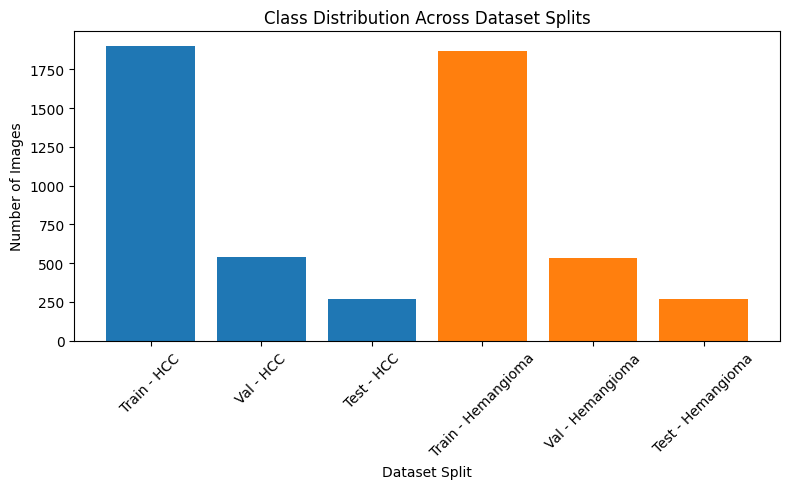

,Split,Class,Count
0,Train,HCC,1901
1,Train,Hemangioma,1868
2,Val,HCC,543
3,Val,Hemangioma,533
4,Test,HCC,272
5,Test,Hemangioma,268


In [ ]:
# =========================
# VISUALIZE CLASS COUNTS
# =========================

import matplotlib.pyplot as plt
import pandas as pd

counts = {
    "Split": ["Train", "Train", "Val", "Val", "Test", "Test"],
    "Class": ["HCC", "Hemangioma", "HCC", "Hemangioma", "HCC", "Hemangioma"],
    "Count": [1901, 1868, 543, 533, 272, 268]
}

df_counts = pd.DataFrame(counts)

plt.figure(figsize=(8, 5))

for cls in df_counts["Class"].unique():
    subset = df_counts[df_counts["Class"] == cls]
    plt.bar(
        subset["Split"] + " - " + subset["Class"],
        subset["Count"]
    )

plt.title("Class Distribution Across Dataset Splits")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

df_counts

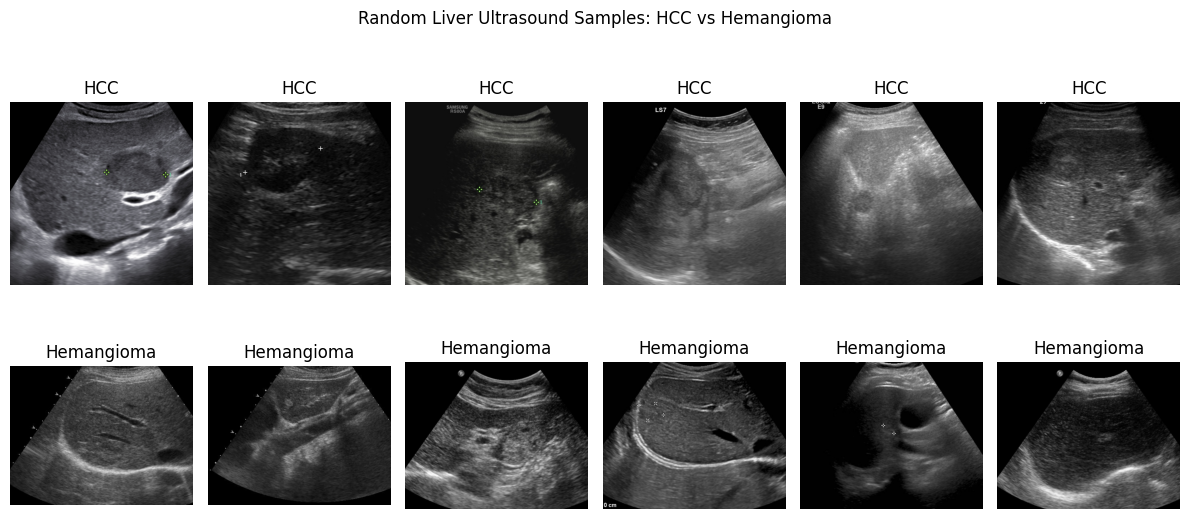

In [ ]:
# =========================
# DISPLAY RANDOM SAMPLE IMAGES BY CLASS
# =========================

import os
import random
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

train_dir = Path("/content/drive/MyDrive/split_for_train/train")

classes = ["HCC", "Hemangioma"]
num_images_per_class = 6

plt.figure(figsize=(12, 6))

plot_index = 1

for cls in classes:
    class_path = train_dir / cls
    image_files = list(class_path.rglob("*"))
    image_files = [f for f in image_files if f.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"]]

    selected_images = random.sample(image_files, num_images_per_class)

    for img_path in selected_images:
        img = Image.open(img_path).convert("RGB")

        plt.subplot(len(classes), num_images_per_class, plot_index)
        plt.imshow(img)
        plt.title(cls)
        plt.axis("off")

        plot_index += 1

plt.suptitle("Random Liver Ultrasound Samples: HCC vs Hemangioma")
plt.tight_layout()
plt.show()

In [ ]:
# =========================
# IMAGE SIZE DISTRIBUTION
# =========================

from pathlib import Path
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

base_dir = Path("/content/drive/MyDrive/split_for_train")

valid_exts = [".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"]

image_info = []

for split in ["train", "val", "test"]:
    split_path = base_dir / split

    for cls in ["HCC", "Hemangioma"]:
        class_path = split_path / cls

        for img_path in class_path.rglob("*"):
            if img_path.suffix.lower() in valid_exts:
                try:
                    img = Image.open(img_path)
                    width, height = img.size

                    image_info.append({
                        "split": split,
                        "class": cls,
                        "width": width,
                        "height": height,
                        "path": str(img_path)
                    })

                except Exception as e:
                    print("Error reading:", img_path, e)

df_images = pd.DataFrame(image_info)

print(df_images.head())
print("\nTotal images checked:", len(df_images))

print("\nImage size summary:")
print(df_images[["width", "height"]].describe())

   split class  width  height  \
0  train   HCC    512     512   
1  train   HCC    512     512   
2  train   HCC    512     512   
3  train   HCC    512     512   
4  train   HCC    512     512   

                                                path  
0  /content/drive/MyDrive/split_for_train/train/H...  
1  /content/drive/MyDrive/split_for_train/train/H...  
2  /content/drive/MyDrive/split_for_train/train/H...  
3  /content/drive/MyDrive/split_for_train/train/H...  
4  /content/drive/MyDrive/split_for_train/train/H...  

Total images checked: 5385

Image size summary:
             width       height
count  5385.000000  5385.000000
mean    615.690808   544.877623
std     117.895460    57.497752
min     353.000000   341.000000
25%     512.000000   512.000000
50%     512.000000   512.000000
75%     735.000000   592.000000
max    1051.000000   848.000000


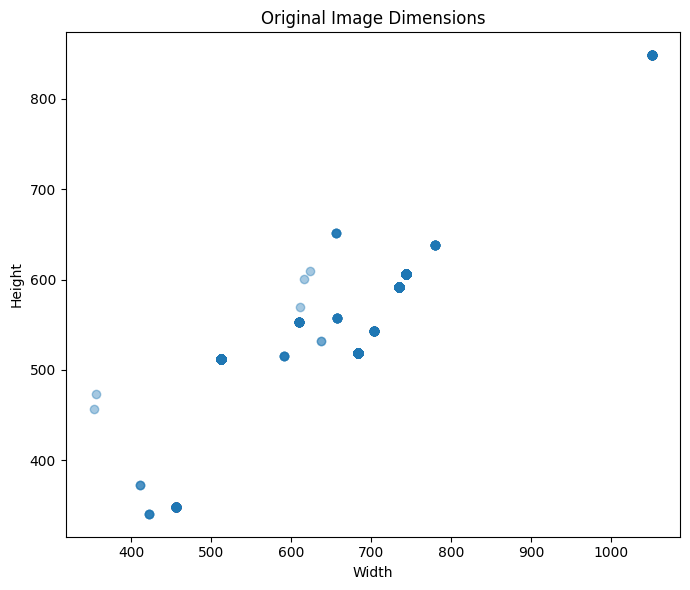

In [ ]:
# =========================
# SCATTER PLOT OF IMAGE DIMENSIONS
# =========================

plt.figure(figsize=(7, 6))
plt.scatter(df_images["width"], df_images["height"], alpha=0.4)
plt.title("Original Image Dimensions")
plt.xlabel("Width")
plt.ylabel("Height")
plt.tight_layout()
plt.show()

In [ ]:
# =========================
# IMAGE SIZE SUMMARY BY CLASS
# =========================

df_images.groupby("class")[["width", "height"]].describe()

width                                                             \
             count        mean        std    min    25%    50%    75%     max   
class                                                                           
HCC         2716.0  512.000000   0.000000  512.0  512.0  512.0  512.0   512.0   
Hemangioma  2669.0  721.207568  77.237059  353.0  735.0  735.0  735.0  1051.0   

            height                                                            
             count        mean        std    min    25%    50%    75%    max  
class                                                                         
HCC         2716.0  512.000000   0.000000  512.0  512.0  512.0  512.0  512.0  
Hemangioma  2669.0  578.334208  66.718163  341.0  592.0  592.0  592.0  848.0

In [ ]:
# =========================
# TRAINING CONSTANTS
# =========================

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20
SEED = 42

num_classes = 1  # binary classification: HCC vs Hemangioma

In [ ]:
# =========================
# DATA AUGMENTATION
# =========================

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

NameError: name 'layers' is not defined

In [ ]:
# =========================
# BUILD EFFICIENTNETB0 MODEL
# =========================

from tensorflow.keras.applications import EfficientNetB0

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Freeze the pretrained base first
base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs)

model.summary()

In [ ]:
# =========================
# COMPILE MODEL
# =========================

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

In [ ]:
# =========================
# CALLBACKS
# =========================

checkpoint_path = "/content/drive/MyDrive/best_effnetb0_smc_lud.keras"

callbacks = [
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

In [ ]:
# =========================
# TRAIN MODEL
# =========================

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6855 - auc: 0.7578 - loss: 0.5749 - precision: 0.6652 - recall: 0.7067
Epoch 1: val_auc improved from None to 0.97202, saving model to /content/drive/MyDrive/best_effnetb0_smc_lud.keras

Epoch 1: finished saving model to /content/drive/MyDrive/best_effnetb0_smc_lud.keras
118/118 ━━━━━━━━━━━━━━━━━━━━ 412s 3s/step - accuracy: 0.7822 - auc: 0.8766 - loss: 0.4740 - precision: 0.7678 - recall: 0.8035 - val_accuracy: 0.9182 - val_auc: 0.9720 - val_loss: 0.3016 - val_precision: 0.9513 - val_recall: 0.8799 - learning_rate: 0.0010
Epoch 2/20
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8908 - auc: 0.9535 - loss: 0.3211 - precision: 0.8776 - recall: 0.8988
Epoch 2: val_auc improved from 0.97202 to 0.98041, saving model to /content/drive/MyDrive/best_effnetb0_smc_lud.keras

Epoch 2: finished saving model to /content/drive/MyDrive/best_effnetb0_smc_lud.keras
118/118 ━━━━━━━━━━━━━━━━━━━━ 389s 3s/step - accuracy: 0.9000 - auc:

KeyboardInterrupt: 

In [ ]:
# =========================
# LOAD BEST SAVED MODEL
# =========================

best_model_path = "/content/drive/MyDrive/best_effnetb0_smc_lud.keras"

best_model = keras.models.load_model(best_model_path)

print("Best model loaded successfully.")

Best model loaded successfully.


Best model loaded successfully.
Found 540 files belonging to 2 classes.
Class names: ['HCC', 'Hemangioma']
Important: 0 = HCC, 1 = Hemangioma

Prediction complete.
Number of test images: 540

TEST SET PERFORMANCE
Accuracy: 0.9241
AUC: 0.9943

HCC metrics:
HCC precision: 0.8738
HCC sensitivity/recall: 0.9926
HCC F1-score: 0.9294

Hemangioma metrics:
Hemangioma precision: 0.9913
Hemangioma sensitivity/recall: 0.8545
Hemangioma F1-score: 0.9178

Confusion Matrix:
[[270   2]
 [ 39 229]]

Classification Report:
              precision    recall  f1-score   support

         HCC       0.87      0.99      0.93       272
  Hemangioma       0.99      0.85      0.92       268

    accuracy                           0.92       540
   macro avg       0.93      0.92      0.92       540
weighted avg       0.93      0.92      0.92       540



,Metric,Value
0,Accuracy,0.924074
1,AUC,0.994293
2,HCC Precision,0.873786
3,HCC Sensitivity/Recall,0.992647
4,HCC F1-score,0.929432
5,Hemangioma Precision,0.991342
6,Hemangioma Sensitivity/Recall,0.854478
7,Hemangioma F1-score,0.917836



Metrics saved to: /content/drive/MyDrive/smc_lud_test_metrics.csv


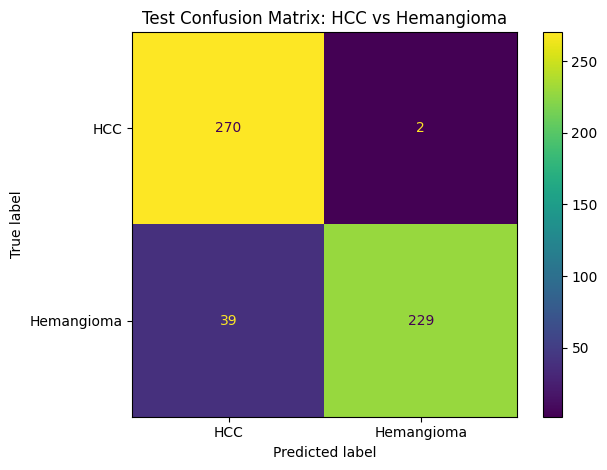

Confusion matrix saved to: /content/drive/MyDrive/smc_lud_confusion_matrix.png


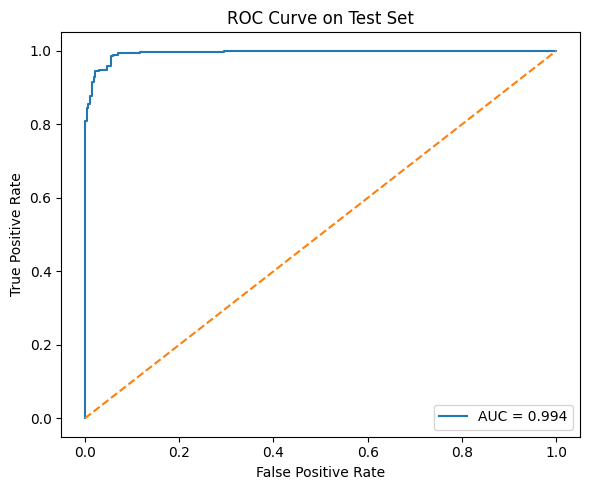

ROC curve saved to: /content/drive/MyDrive/smc_lud_roc_curve.png


In [ ]:
# =========================
# TEST BEST SAVED MODEL
# =========================

import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve
)

# -------------------------
# 1. Load best saved model
# -------------------------

best_model_path = "/content/drive/MyDrive/best_effnetb0_smc_lud.keras"

best_model = keras.models.load_model(best_model_path)

print("Best model loaded successfully.")


# -------------------------
# 2. Load test dataset
# -------------------------

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

test_dir = "/content/drive/MyDrive/split_for_train/test"

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = test_ds.class_names
print("Class names:", class_names)
print("Important: 0 = HCC, 1 = Hemangioma")


# -------------------------
# 3. Predict on test set
# -------------------------

y_true = []
y_prob = []

for images, labels in test_ds:
    probs = best_model.predict(images, verbose=0)
    y_prob.extend(probs.ravel())
    y_true.extend(labels.numpy().ravel())

y_true = np.array(y_true).astype(int)
y_prob = np.array(y_prob)

# Sigmoid output: probability closer to 1 = Hemangioma
y_pred = (y_prob >= 0.5).astype(int)

print("\nPrediction complete.")
print("Number of test images:", len(y_true))


# -------------------------
# 4. Calculate metrics
# -------------------------

acc = accuracy_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)

# Hemangioma is positive class because label 1 = Hemangioma
precision_hema = precision_score(y_true, y_pred, pos_label=1)
recall_hema = recall_score(y_true, y_pred, pos_label=1)
f1_hema = f1_score(y_true, y_pred, pos_label=1)

# HCC as positive class using pos_label=0
precision_hcc = precision_score(y_true, y_pred, pos_label=0)
recall_hcc = recall_score(y_true, y_pred, pos_label=0)  # HCC sensitivity
f1_hcc = f1_score(y_true, y_pred, pos_label=0)

cm = confusion_matrix(y_true, y_pred)

print("\n=========================")
print("TEST SET PERFORMANCE")
print("=========================")
print(f"Accuracy: {acc:.4f}")
print(f"AUC: {auc:.4f}")

print("\nHCC metrics:")
print(f"HCC precision: {precision_hcc:.4f}")
print(f"HCC sensitivity/recall: {recall_hcc:.4f}")
print(f"HCC F1-score: {f1_hcc:.4f}")

print("\nHemangioma metrics:")
print(f"Hemangioma precision: {precision_hema:.4f}")
print(f"Hemangioma sensitivity/recall: {recall_hema:.4f}")
print(f"Hemangioma F1-score: {f1_hema:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))


# -------------------------
# 5. Save metrics as table
# -------------------------

results_table = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "AUC",
        "HCC Precision",
        "HCC Sensitivity/Recall",
        "HCC F1-score",
        "Hemangioma Precision",
        "Hemangioma Sensitivity/Recall",
        "Hemangioma F1-score"
    ],
    "Value": [
        acc,
        auc,
        precision_hcc,
        recall_hcc,
        f1_hcc,
        precision_hema,
        recall_hema,
        f1_hema
    ]
})

display(results_table)

results_table.to_csv("/content/drive/MyDrive/smc_lud_test_metrics.csv", index=False)
print("\nMetrics saved to: /content/drive/MyDrive/smc_lud_test_metrics.csv")


# -------------------------
# 6. Plot confusion matrix
# -------------------------

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(values_format="d")
plt.title("Test Confusion Matrix: HCC vs Hemangioma")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/smc_lud_confusion_matrix.png", dpi=300)
plt.show()

print("Confusion matrix saved to: /content/drive/MyDrive/smc_lud_confusion_matrix.png")


# -------------------------
# 7. Plot ROC curve
# -------------------------

fpr, tpr, thresholds = roc_curve(y_true, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve on Test Set")
plt.legend()
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/smc_lud_roc_curve.png", dpi=300)
plt.show()

print("ROC curve saved to: /content/drive/MyDrive/smc_lud_roc_curve.png")

TensorFlow GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Found 3769 files belonging to 2 classes.
Found 1076 files belonging to 2 classes.
Found 540 files belonging to 2 classes.
Class names: ['HCC', 'Hemangioma']
Important: 0 = HCC, 1 = Hemangioma
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.6262 - auc: 0.6663 - loss: 0.6827 - precision: 0.6137 - recall: 0.6052
Epoch 1: val_auc improved from None to 0.95873, saving model to /content/drive/MyDrive/best_mobilenetv2_smc_lud.keras

Epoch 1: finished saving model to /content/drive/MyDrive/best_mobilenetv2_smc_lud.keras
118/118 ━━━━━━━━━━━━━━━━━━━━ 845s 7s/step - accuracy: 0.7368 - auc: 0.8181 - loss: 0.5211 - precision: 0.7320 - recall: 0.7398 - val_accuracy: 0.8866 - val_auc: 0.9587 - val_loss: 0.2990 - val_precision: 0.8624 - val_recall: 0.9174 - learning_rate: 0.0010
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step - accuracy: 0.8466 - auc: 0.9299 - loss: 0.3433 - precision: 0.8413 - recall: 0.8420
Epoch 2: val_auc improved from 0.95873 to 0.97034, saving model to /content/drive/MyDrive/best_mobilenetv2_smc_lud.keras

Epoch 2: finished saving model to /content/drive/MyDrive/best_mobilenetv2_smc_lud.keras
118/118 ━━━━━━━━━━━━━━━━━━━━ 27s 229ms/step - accura

,Model,Metric,Value
0,MobileNetV2,Accuracy,0.946296
1,MobileNetV2,AUC,0.991810
2,MobileNetV2,HCC Precision,0.951673
3,MobileNetV2,HCC Sensitivity/Recall,0.941176
4,MobileNetV2,HCC F1-score,0.946396
5,MobileNetV2,Hemangioma Precision,0.940959
6,MobileNetV2,Hemangioma Sensitivity/Recall,0.951493
7,MobileNetV2,Hemangioma F1-score,0.946197



Metrics saved to: /content/drive/MyDrive/mobilenetv2_smc_lud_test_metrics.csv


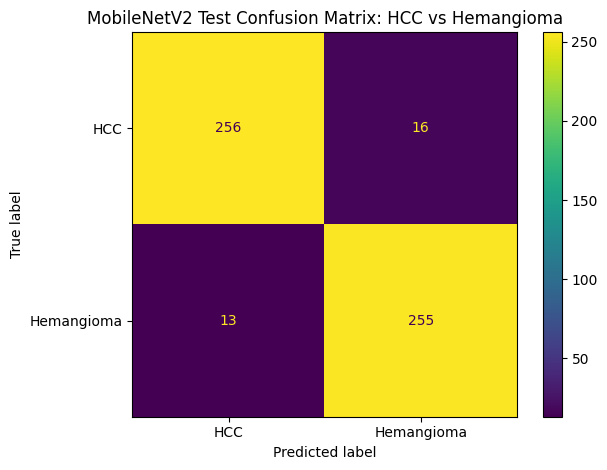

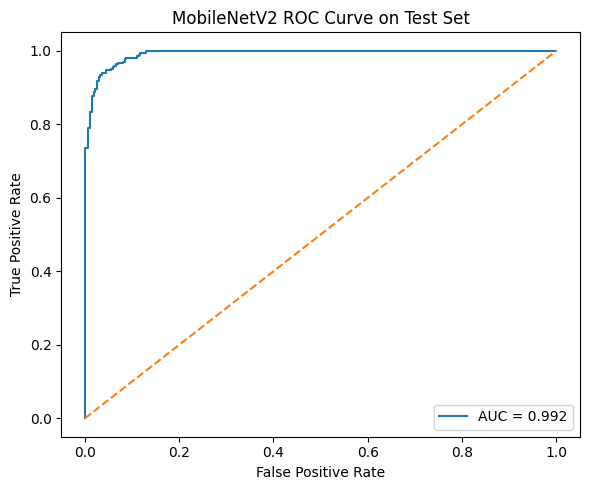

Done.


In [ ]:
# =========================
# TRAIN SECOND MODEL: MobileNetV2
# =========================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve
)

# -------------------------
# 1. Check GPU
# -------------------------

print("TensorFlow GPUs:", tf.config.list_physical_devices("GPU"))

# -------------------------
# 2. Define paths and constants
# -------------------------

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
EPOCHS = 10

train_dir = "/content/drive/MyDrive/split_for_train/train"
val_dir = "/content/drive/MyDrive/split_for_train/val"
test_dir = "/content/drive/MyDrive/split_for_train/test"

# -------------------------
# 3. Load datasets
# -------------------------

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_ds.class_names
print("Class names:", class_names)
print("Important: 0 = HCC, 1 = Hemangioma")

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# -------------------------
# 4. Data augmentation
# -------------------------

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

# -------------------------
# 5. Build MobileNetV2 model
# -------------------------

base_model = MobileNetV2(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

mobilenet_model = keras.Model(inputs, outputs)

mobilenet_model.summary()

# -------------------------
# 6. Compile model
# -------------------------

mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.AUC(name="auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

# -------------------------
# 7. Callbacks
# -------------------------

checkpoint_path = "/content/drive/MyDrive/best_mobilenetv2_smc_lud.keras"

callbacks = [
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=1,
        min_lr=1e-6,
        verbose=1
    )
]

# -------------------------
# 8. Train model
# -------------------------

history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

# -------------------------
# 9. Load best MobileNetV2 model
# -------------------------

best_mobilenet = keras.models.load_model(checkpoint_path)

print("Best MobileNetV2 model loaded.")

# -------------------------
# 10. Predict on test set
# -------------------------

y_true = []
y_prob = []

for images, labels in test_ds:
    probs = best_mobilenet.predict(images, verbose=0)
    y_prob.extend(probs.ravel())
    y_true.extend(labels.numpy().ravel())

y_true = np.array(y_true).astype(int)
y_prob = np.array(y_prob)

y_pred = (y_prob >= 0.5).astype(int)

# -------------------------
# 11. Calculate test metrics
# -------------------------

acc = accuracy_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)

precision_hcc = precision_score(y_true, y_pred, pos_label=0)
recall_hcc = recall_score(y_true, y_pred, pos_label=0)
f1_hcc = f1_score(y_true, y_pred, pos_label=0)

precision_hema = precision_score(y_true, y_pred, pos_label=1)
recall_hema = recall_score(y_true, y_pred, pos_label=1)
f1_hema = f1_score(y_true, y_pred, pos_label=1)

cm = confusion_matrix(y_true, y_pred)

print("\n=========================")
print("MobileNetV2 TEST SET PERFORMANCE")
print("=========================")
print(f"Accuracy: {acc:.4f}")
print(f"AUC: {auc:.4f}")

print("\nHCC metrics:")
print(f"HCC precision: {precision_hcc:.4f}")
print(f"HCC sensitivity/recall: {recall_hcc:.4f}")
print(f"HCC F1-score: {f1_hcc:.4f}")

print("\nHemangioma metrics:")
print(f"Hemangioma precision: {precision_hema:.4f}")
print(f"Hemangioma sensitivity/recall: {recall_hema:.4f}")
print(f"Hemangioma F1-score: {f1_hema:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# -------------------------
# 12. Save results table
# -------------------------

mobilenet_results = pd.DataFrame({
    "Model": ["MobileNetV2"] * 8,
    "Metric": [
        "Accuracy",
        "AUC",
        "HCC Precision",
        "HCC Sensitivity/Recall",
        "HCC F1-score",
        "Hemangioma Precision",
        "Hemangioma Sensitivity/Recall",
        "Hemangioma F1-score"
    ],
    "Value": [
        acc,
        auc,
        precision_hcc,
        recall_hcc,
        f1_hcc,
        precision_hema,
        recall_hema,
        f1_hema
    ]
})

display(mobilenet_results)

mobilenet_results.to_csv("/content/drive/MyDrive/mobilenetv2_smc_lud_test_metrics.csv", index=False)

print("\nMetrics saved to: /content/drive/MyDrive/mobilenetv2_smc_lud_test_metrics.csv")

# -------------------------
# 13. Plot confusion matrix
# -------------------------

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(values_format="d")
plt.title("MobileNetV2 Test Confusion Matrix: HCC vs Hemangioma")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/mobilenetv2_smc_lud_confusion_matrix.png", dpi=300)
plt.show()

# -------------------------
# 14. Plot ROC curve
# -------------------------

fpr, tpr, thresholds = roc_curve(y_true, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("MobileNetV2 ROC Curve on Test Set")
plt.legend()
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/mobilenetv2_smc_lud_roc_curve.png", dpi=300)
plt.show()

print("Done.")

Device: cuda
GPU name: Tesla T4
Class names: ['HCC', 'Hemangioma']
Important: 0 = HCC, 1 = Hemangioma
Train images: 3769
Val images: 1076
Test images: 540


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/22.9M [00:00<?, ?B/s]

ViT model loaded.

Epoch 1/10
------------------------------


/tmp/ipykernel_21858/3384848059.py:177: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/tmp/ipykernel_21858/3384848059.py:239: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_21858/3384848059.py:194: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


...

,epoch,train_loss,train_accuracy,train_auc,val_accuracy,val_auc
0,1,0.163925,0.928628,0.983195,0.992565,0.999960
1,2,0.044203,0.988326,0.997723,0.993494,0.999895
2,3,0.025673,0.992040,0.998888,0.995353,0.999834
3,4,0.012496,0.995490,0.999817,0.993494,0.999903


/tmp/ipykernel_21858/3384848059.py:194: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():



ViT-Tiny TEST SET PERFORMANCE
Accuracy: 0.9963
AUC: 1.0000

HCC metrics:
HCC precision: 1.0000
HCC sensitivity/recall: 0.9926
HCC F1-score: 0.9963

Hemangioma metrics:
Hemangioma precision: 0.9926
Hemangioma sensitivity/recall: 1.0000
Hemangioma F1-score: 0.9963

Confusion Matrix:
[[270   2]
 [  0 268]]

Classification Report:
              precision    recall  f1-score   support

         HCC       1.00      0.99      1.00       272
  Hemangioma       0.99      1.00      1.00       268

    accuracy                           1.00       540
   macro avg       1.00      1.00      1.00       540
weighted avg       1.00      1.00      1.00       540



,Model,Metric,Value
0,ViT-Tiny,Accuracy,0.996296
1,ViT-Tiny,AUC,0.999986
2,ViT-Tiny,HCC Precision,1.000000
3,ViT-Tiny,HCC Sensitivity/Recall,0.992647
4,ViT-Tiny,HCC F1-score,0.996310
5,ViT-Tiny,Hemangioma Precision,0.992593
6,ViT-Tiny,Hemangioma Sensitivity/Recall,1.000000
7,ViT-Tiny,Hemangioma F1-score,0.996283



Metrics saved to: /content/drive/MyDrive/vit_tiny_smc_lud_test_metrics.csv


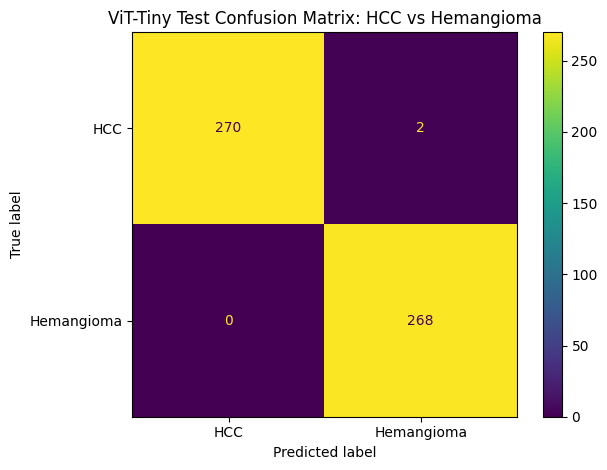

Confusion matrix saved to: /content/drive/MyDrive/vit_tiny_smc_lud_confusion_matrix.png


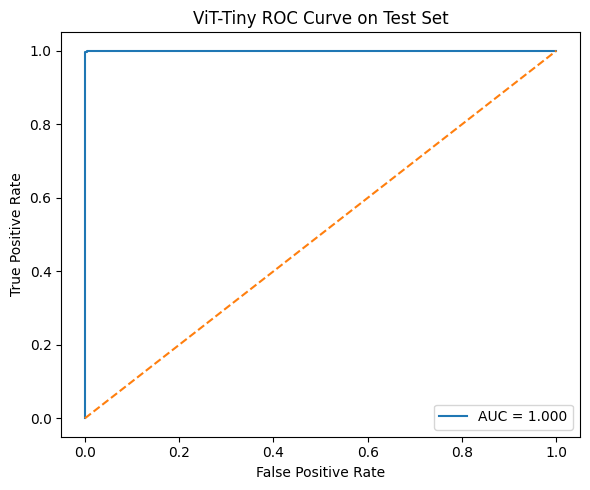

ROC curve saved to: /content/drive/MyDrive/vit_tiny_smc_lud_roc_curve.png
Done.


In [ ]:
# =========================
# TRAIN THIRD MODEL: Vision Transformer (ViT-Tiny)
# HCC vs Hemangioma using SMC-LUD Dataset
# =========================

# Install timm if not already installed
!pip install -q timm

import os
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

from torchvision import datasets, transforms

import timm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve
)

# -------------------------
# 1. Check GPU
# -------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if device.type != "cuda":
    raise RuntimeError("No GPU detected. Stop now and switch Colab runtime to T4 GPU before training ViT.")

print("GPU name:", torch.cuda.get_device_name(0))

# -------------------------
# 2. Reproducibility
# -------------------------

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# -------------------------
# 3. Define paths and constants
# -------------------------

train_dir = "/content/drive/MyDrive/split_for_train/train"
val_dir   = "/content/drive/MyDrive/split_for_train/val"
test_dir  = "/content/drive/MyDrive/split_for_train/test"

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 10
LEARNING_RATE = 1e-4
PATIENCE = 3

# -------------------------
# 4. Image transforms
# -------------------------

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(5),
    transforms.ColorJitter(contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_test_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# -------------------------
# 5. Load datasets
# -------------------------

train_dataset = datasets.ImageFolder(train_dir, transform=train_transforms)
val_dataset   = datasets.ImageFolder(val_dir, transform=val_test_transforms)
test_dataset  = datasets.ImageFolder(test_dir, transform=val_test_transforms)

class_names = train_dataset.classes
print("Class names:", class_names)
print("Important: 0 = HCC, 1 = Hemangioma")

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train images:", len(train_dataset))
print("Val images:", len(val_dataset))
print("Test images:", len(test_dataset))

# -------------------------
# 6. Build ViT model
# -------------------------

# ViT-Tiny is faster and suitable for comparison.
# You can later change to 'vit_base_patch16_224' if you have stronger GPU time.
model = timm.create_model(
    "vit_tiny_patch16_224",
    pretrained=True,
    num_classes=1
)

model = model.to(device)

print("ViT model loaded.")

# -------------------------
# 7. Loss, optimizer, scheduler
# -------------------------

criterion = nn.BCEWithLogitsLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.3,
    patience=1
)

# Mixed precision for faster GPU training
scaler = torch.cuda.amp.GradScaler()

# -------------------------
# 8. Helper function: evaluate
# -------------------------

def evaluate_model(model, data_loader):
    model.eval()

    all_labels = []
    all_probs = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.float().to(device)

            with torch.cuda.amp.autocast():
                outputs = model(images).squeeze(1)
                probs = torch.sigmoid(outputs)

            all_probs.extend(probs.detach().cpu().numpy())
            all_labels.extend(labels.detach().cpu().numpy())

    all_labels = np.array(all_labels).astype(int)
    all_probs = np.array(all_probs)

    all_preds = (all_probs >= 0.5).astype(int)

    acc = accuracy_score(all_labels, all_preds)
    auc = roc_auc_score(all_labels, all_probs)

    return acc, auc, all_labels, all_probs, all_preds

# -------------------------
# 9. Train ViT
# -------------------------

best_val_auc = 0
best_model_wts = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0

history = []

start_time = time.time()

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print("-" * 30)

    model.train()

    running_loss = 0.0
    train_labels = []
    train_probs = []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.float().to(device)

        optimizer.zero_grad()

        with torch.cuda.amp.autocast():
            outputs = model(images).squeeze(1)
            loss = criterion(outputs, labels)
            probs = torch.sigmoid(outputs)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)

        train_labels.extend(labels.detach().cpu().numpy())
        train_probs.extend(probs.detach().cpu().numpy())

    epoch_loss = running_loss / len(train_dataset)

    train_labels = np.array(train_labels).astype(int)
    train_probs = np.array(train_probs)
    train_preds = (train_probs >= 0.5).astype(int)

    train_acc = accuracy_score(train_labels, train_preds)
    train_auc = roc_auc_score(train_labels, train_probs)

    val_acc, val_auc, _, _, _ = evaluate_model(model, val_loader)

    scheduler.step(val_auc)

    print(f"Train Loss: {epoch_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Train AUC: {train_auc:.4f}")
    print(f"Val Accuracy: {val_acc:.4f}")
    print(f"Val AUC: {val_auc:.4f}")

    history.append({
        "epoch": epoch + 1,
        "train_loss": epoch_loss,
        "train_accuracy": train_acc,
        "train_auc": train_auc,
        "val_accuracy": val_acc,
        "val_auc": val_auc
    })

    if val_auc > best_val_auc:
        print(f"Val AUC improved from {best_val_auc:.4f} to {val_auc:.4f}. Saving model.")
        best_val_auc = val_auc
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save(model.state_dict(), "/content/drive/MyDrive/best_vit_tiny_smc_lud.pth")
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        print(f"Val AUC did not improve. Patience: {epochs_without_improvement}/{PATIENCE}")

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

training_time = time.time() - start_time
print(f"\nTraining complete in {training_time/60:.2f} minutes.")
print(f"Best validation AUC: {best_val_auc:.4f}")

# Load best weights
model.load_state_dict(best_model_wts)

# Save training history
history_df = pd.DataFrame(history)
history_df.to_csv("/content/drive/MyDrive/vit_tiny_training_history.csv", index=False)
display(history_df)

# -------------------------
# 10. Test best ViT model
# -------------------------

test_acc, test_auc, y_true, y_prob, y_pred = evaluate_model(model, test_loader)

precision_hcc = precision_score(y_true, y_pred, pos_label=0)
recall_hcc = recall_score(y_true, y_pred, pos_label=0)
f1_hcc = f1_score(y_true, y_pred, pos_label=0)

precision_hema = precision_score(y_true, y_pred, pos_label=1)
recall_hema = recall_score(y_true, y_pred, pos_label=1)
f1_hema = f1_score(y_true, y_pred, pos_label=1)

cm = confusion_matrix(y_true, y_pred)

print("\n=========================")
print("ViT-Tiny TEST SET PERFORMANCE")
print("=========================")
print(f"Accuracy: {test_acc:.4f}")
print(f"AUC: {test_auc:.4f}")

print("\nHCC metrics:")
print(f"HCC precision: {precision_hcc:.4f}")
print(f"HCC sensitivity/recall: {recall_hcc:.4f}")
print(f"HCC F1-score: {f1_hcc:.4f}")

print("\nHemangioma metrics:")
print(f"Hemangioma precision: {precision_hema:.4f}")
print(f"Hemangioma sensitivity/recall: {recall_hema:.4f}")
print(f"Hemangioma F1-score: {f1_hema:.4f}")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# -------------------------
# 11. Save results table
# -------------------------

vit_results = pd.DataFrame({
    "Model": ["ViT-Tiny"] * 8,
    "Metric": [
        "Accuracy",
        "AUC",
        "HCC Precision",
        "HCC Sensitivity/Recall",
        "HCC F1-score",
        "Hemangioma Precision",
        "Hemangioma Sensitivity/Recall",
        "Hemangioma F1-score"
    ],
    "Value": [
        test_acc,
        test_auc,
        precision_hcc,
        recall_hcc,
        f1_hcc,
        precision_hema,
        recall_hema,
        f1_hema
    ]
})

display(vit_results)

vit_results.to_csv("/content/drive/MyDrive/vit_tiny_smc_lud_test_metrics.csv", index=False)
print("\nMetrics saved to: /content/drive/MyDrive/vit_tiny_smc_lud_test_metrics.csv")

# -------------------------
# 12. Plot confusion matrix
# -------------------------

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(values_format="d")
plt.title("ViT-Tiny Test Confusion Matrix: HCC vs Hemangioma")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/vit_tiny_smc_lud_confusion_matrix.png", dpi=300)
plt.show()

print("Confusion matrix saved to: /content/drive/MyDrive/vit_tiny_smc_lud_confusion_matrix.png")

# -------------------------
# 13. Plot ROC curve
# -------------------------

fpr, tpr, thresholds = roc_curve(y_true, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {test_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ViT-Tiny ROC Curve on Test Set")
plt.legend()
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/vit_tiny_smc_lud_roc_curve.png", dpi=300)
plt.show()

print("ROC curve saved to: /content/drive/MyDrive/vit_tiny_smc_lud_roc_curve.png")
print("Done.")

In [ ]:
# =========================
# CHECK MISSED HCC CASES AND CONFIDENCE - ViT-Tiny
# =========================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Make sure model is in evaluation mode
model.eval()

missed_hcc_cases = []

# ImageFolder stores file paths here
test_image_paths = [sample[0] for sample in test_dataset.samples]

all_index = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        with torch.cuda.amp.autocast():
            outputs = model(images).squeeze(1)
            probs_hema = torch.sigmoid(outputs)

        probs_hema = probs_hema.detach().cpu().numpy()
        labels_np = labels.detach().cpu().numpy().astype(int)

        # Prediction: probability >= 0.5 means Hemangioma
        preds = (probs_hema >= 0.5).astype(int)

        for i in range(len(labels_np)):
            true_label = labels_np[i]
            pred_label = preds[i]
            prob_hema = probs_hema[i]
            prob_hcc = 1 - prob_hema

            # Missed HCC = true HCC but predicted Hemangioma
            if true_label == 0 and pred_label == 1:
                missed_hcc_cases.append({
                    "index": all_index,
                    "image_path": test_image_paths[all_index],
                    "true_label": "HCC",
                    "predicted_label": "Hemangioma",
                    "probability_HCC": prob_hcc,
                    "probability_Hemangioma": prob_hema,
                    "confidence_in_wrong_prediction": prob_hema
                })

            all_index += 1

missed_hcc_df = pd.DataFrame(missed_hcc_cases)

print("Number of missed HCC cases:", len(missed_hcc_df))
display(missed_hcc_df)

# Save missed cases table
missed_hcc_df.to_csv("/content/drive/MyDrive/vit_tiny_missed_hcc_cases.csv", index=False)
print("Saved to: /content/drive/MyDrive/vit_tiny_missed_hcc_cases.csv")

/tmp/ipykernel_21858/2371582594.py:26: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Number of missed HCC cases: 2


/usr/local/lib/python3.12/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,index,image_path,true_label,predicted_label,probability_HCC,probability_Hemangioma,confidence_in_wrong_prediction
0,74,/content/drive/MyDrive/split_for_train/test/HC...,HCC,Hemangioma,0.438965,0.561035,0.561035
1,76,/content/drive/MyDrive/split_for_train/test/HC...,HCC,Hemangioma,0.142578,0.857422,0.857422


Saved to: /content/drive/MyDrive/vit_tiny_missed_hcc_cases.csv


#Pertubation experiment

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
GPU name: Tesla T4
Train folder exists: True
Validation folder exists: True
Test folder exists: True
Saved ViT model exists: True
Class names: ['HCC', 'Hemangioma']
Important: 0 = HCC, 1 = Hemangioma
Number of test images: 540
Saved ViT-Tiny model loaded successfully.

CLEAN TEST PERFORMANCE
Accuracy: 0.9963
AUC: 1.0000
HCC Precision: 1.0000
HCC Sensitivity: 0.9926
HCC F1-score: 0.9963
Hemangioma Precision: 0.9926
Hemangioma Sensitivity: 1.0000
Hemangioma F1-score: 0.9963

Confusion Matrix:
[[270   2]
 [  0 268]]

Classification Report:
              precision    recall  f1-score   support

         HCC       1.00      0.99      1.00       272
  Hemangioma       0.99      1.00      1.00       268

    accuracy                           1.00       540
   macro avg       1.00      1.00      1.00       540
weighted avg       1.00      1.00      1.00

,Epsilon,Accuracy,AUC,HCC Precision,HCC Sensitivity,HCC F1-score,Hemangioma Precision,Hemangioma Sensitivity,Hemangioma F1-score
0,0.000,0.996296,0.999986,1.000000,0.992647,0.996310,0.992593,1.000000,0.996283
1,0.001,0.985185,0.999657,0.996241,0.974265,0.985130,0.974453,0.996269,0.985240
2,0.002,0.964815,0.998093,0.988417,0.941176,0.964218,0.943060,0.988806,0.965392
3,0.005,0.894444,0.973373,0.969432,0.816176,0.886228,0.839228,0.973881,0.901554
4,0.010,0.762963,0.853860,0.878947,0.613971,0.722944,0.700000,0.914179,0.792880
5,0.020,0.570370,0.592790,0.685185,0.272059,0.389474,0.541667,0.873134,0.668571



Saved FGSM attack results to:
/content/drive/MyDrive/vit_tiny_fgsm_attack_results.csv


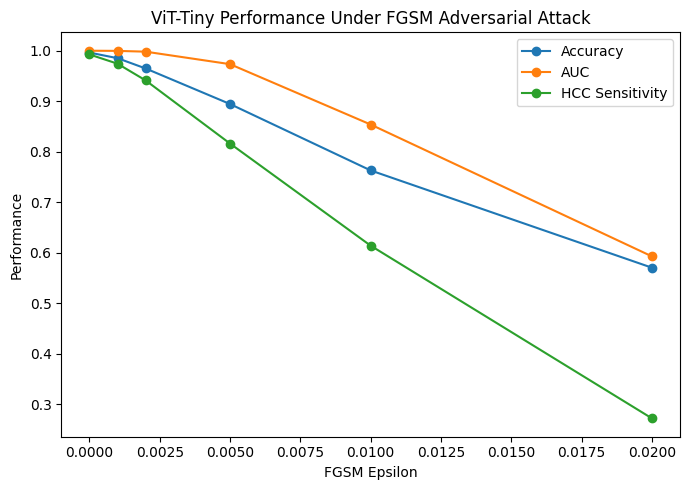

Saved performance plot to:
/content/drive/MyDrive/vit_tiny_fgsm_performance_drop.png


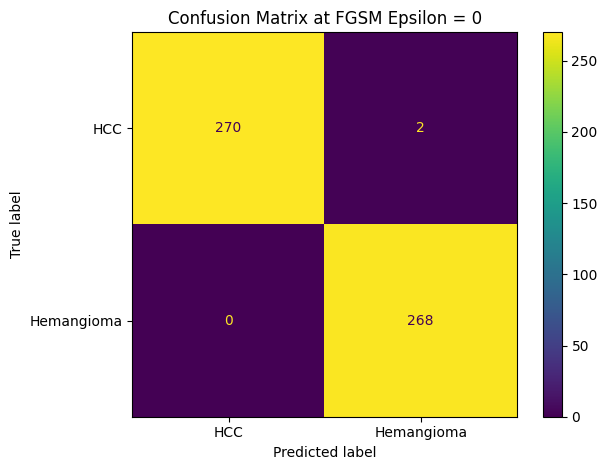

Saved: /content/drive/MyDrive/vit_tiny_fgsm_cm_epsilon_0.png


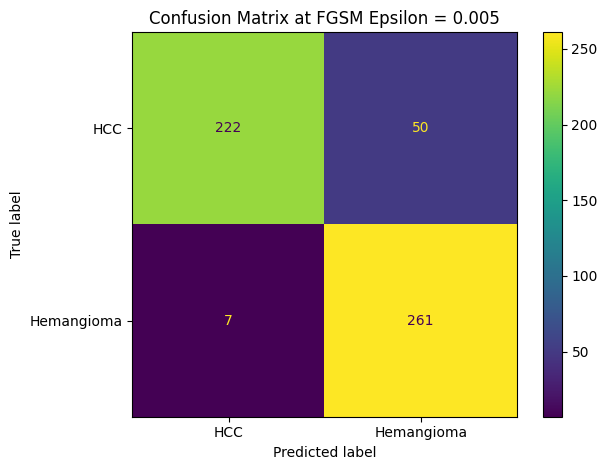

Saved: /content/drive/MyDrive/vit_tiny_fgsm_cm_epsilon_0.005.png


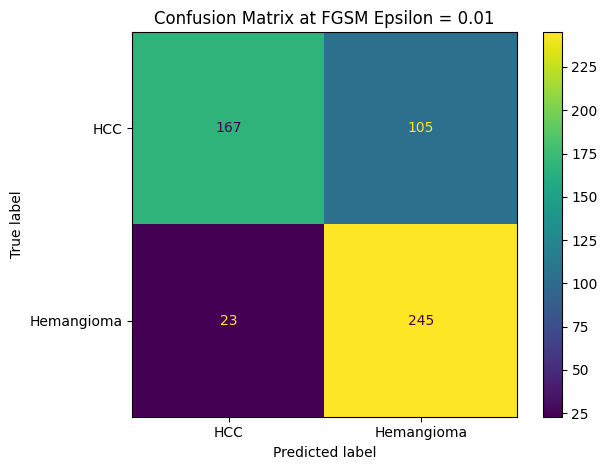

Saved: /content/drive/MyDrive/vit_tiny_fgsm_cm_epsilon_0.01.png


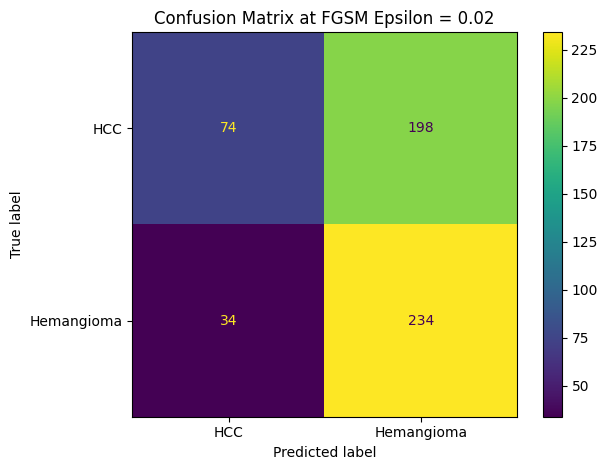

Saved: /content/drive/MyDrive/vit_tiny_fgsm_cm_epsilon_0.02.png


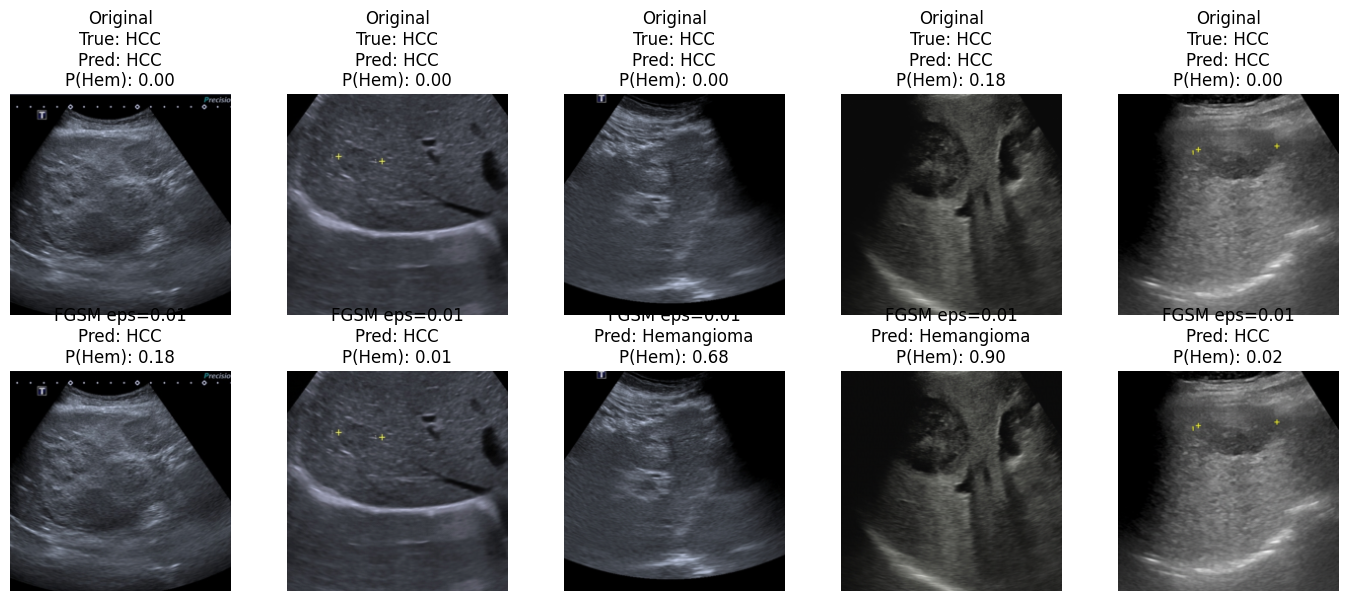

Saved original vs adversarial image panel to:
/content/drive/MyDrive/vit_tiny_fgsm_original_vs_adversarial.png

Number of missed HCC cases at epsilon 0.01:
105


,index,image_path,true_label,predicted_label,probability_HCC,probability_Hemangioma,epsilon
0,2,/content/drive/MyDrive/split_for_train/test/HC...,HCC,Hemangioma,0.323056,0.676944,0.01
1,3,/content/drive/MyDrive/split_for_train/test/HC...,HCC,Hemangioma,0.098449,0.901551,0.01
2,5,/content/drive/MyDrive/split_for_train/test/HC...,HCC,Hemangioma,0.024947,0.975053,0.01
3,7,/content/drive/MyDrive/split_for_train/test/HC...,HCC,Hemangioma,0.097795,0.902205,0.01
4,12,/content/drive/MyDrive/split_for_train/test/HC...,HCC,Hemangioma,0.367230,0.632770,0.01
...,...,...,...,...,...,...,...
100,262,/content/drive/MyDrive/split_for_train/test/HC...,HCC,Hemangioma,0.001185,0.998815,0.01
101,265,/content/drive/MyDrive/split_for_train/test/HC...,HCC,Hemangioma,0.038801,0.961199,0.01
102,267,/content/drive/MyDrive/split_for_train/test/HC...,HCC,Hemangioma,0.407915,0.592085,0.01
103,268,/content/drive/MyDrive/split_for_train/test/HC...,HCC,Hemangioma,0.058382,0.941618,0.01


Saved missed HCC cases to:
/content/drive/MyDrive/vit_tiny_fgsm_missed_hcc_epsilon_0.01.csv

FGSM adversarial attack analysis complete.


In [ ]:
# ============================================================
# ADVERSARIAL ATTACK ON SAVED ViT-Tiny MODEL
# HCC vs Hemangioma using SMC-LUD Dataset
# ============================================================

# -------------------------
# 1. Install and import libraries
# -------------------------

!pip install -q timm

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import timm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve
)

from PIL import Image


# -------------------------
# 2. Mount Google Drive
# -------------------------

from google.colab import drive
drive.mount('/content/drive')


# -------------------------
# 3. Check GPU
# -------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if device.type != "cuda":
    raise RuntimeError("No GPU detected. Go to Runtime > Change runtime type > T4 GPU.")

print("GPU name:", torch.cuda.get_device_name(0))


# -------------------------
# 4. Set random seed
# -------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


# -------------------------
# 5. Define paths
# -------------------------

train_dir = "/content/drive/MyDrive/split_for_train/train"
val_dir   = "/content/drive/MyDrive/split_for_train/val"
test_dir  = "/content/drive/MyDrive/split_for_train/test"

vit_model_path = "/content/drive/MyDrive/best_vit_tiny_smc_lud.pth"

print("Train folder exists:", os.path.exists(train_dir))
print("Validation folder exists:", os.path.exists(val_dir))
print("Test folder exists:", os.path.exists(test_dir))
print("Saved ViT model exists:", os.path.exists(vit_model_path))


# -------------------------
# 6. Define image transforms
# -------------------------

IMG_SIZE = 224
BATCH_SIZE = 32

val_test_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# -------------------------
# 7. Load test dataset
# -------------------------

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=val_test_transforms
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

class_names = test_dataset.classes

print("Class names:", class_names)
print("Important: 0 = HCC, 1 = Hemangioma")
print("Number of test images:", len(test_dataset))


# -------------------------
# 8. Load saved ViT-Tiny model
# -------------------------

model = timm.create_model(
    "vit_tiny_patch16_224",
    pretrained=False,
    num_classes=1
)

model.load_state_dict(
    torch.load(vit_model_path, map_location=device)
)

model = model.to(device)
model.eval()

print("Saved ViT-Tiny model loaded successfully.")


# -------------------------
# 9. Evaluation function for clean images
# -------------------------

def evaluate_clean_model(model, data_loader):
    model.eval()

    all_labels = []
    all_probs = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.float().to(device)

            outputs = model(images).squeeze(1)
            probs = torch.sigmoid(outputs)

            all_probs.extend(probs.detach().cpu().numpy())
            all_labels.extend(labels.detach().cpu().numpy())

    y_true = np.array(all_labels).astype(int)
    y_prob = np.array(all_probs)
    y_pred = (y_prob >= 0.5).astype(int)

    acc = accuracy_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)

    precision_hcc = precision_score(y_true, y_pred, pos_label=0, zero_division=0)
    recall_hcc = recall_score(y_true, y_pred, pos_label=0, zero_division=0)
    f1_hcc = f1_score(y_true, y_pred, pos_label=0, zero_division=0)

    precision_hema = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
    recall_hema = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
    f1_hema = f1_score(y_true, y_pred, pos_label=1, zero_division=0)

    cm = confusion_matrix(y_true, y_pred)

    return {
        "accuracy": acc,
        "auc": auc,
        "hcc_precision": precision_hcc,
        "hcc_sensitivity": recall_hcc,
        "hcc_f1": f1_hcc,
        "hemangioma_precision": precision_hema,
        "hemangioma_sensitivity": recall_hema,
        "hemangioma_f1": f1_hema,
        "confusion_matrix": cm,
        "y_true": y_true,
        "y_prob": y_prob,
        "y_pred": y_pred
    }


# -------------------------
# 10. Confirm clean test performance
# -------------------------

clean_result = evaluate_clean_model(model, test_loader)

print("\n==============================")
print("CLEAN TEST PERFORMANCE")
print("==============================")
print(f"Accuracy: {clean_result['accuracy']:.4f}")
print(f"AUC: {clean_result['auc']:.4f}")
print(f"HCC Precision: {clean_result['hcc_precision']:.4f}")
print(f"HCC Sensitivity: {clean_result['hcc_sensitivity']:.4f}")
print(f"HCC F1-score: {clean_result['hcc_f1']:.4f}")
print(f"Hemangioma Precision: {clean_result['hemangioma_precision']:.4f}")
print(f"Hemangioma Sensitivity: {clean_result['hemangioma_sensitivity']:.4f}")
print(f"Hemangioma F1-score: {clean_result['hemangioma_f1']:.4f}")

print("\nConfusion Matrix:")
print(clean_result["confusion_matrix"])

print("\nClassification Report:")
print(classification_report(
    clean_result["y_true"],
    clean_result["y_pred"],
    target_names=class_names
))


# -------------------------
# 11. Define FGSM adversarial attack
# -------------------------

criterion = nn.BCEWithLogitsLoss()

def fgsm_attack(model, images, labels, epsilon):
    """
    Fast Gradient Sign Method attack.
    Images are already ImageNet-normalized.
    Labels: 0 = HCC, 1 = Hemangioma.
    """

    images = images.clone().detach().to(device)
    labels = labels.float().to(device)

    images.requires_grad = True

    outputs = model(images).squeeze(1)
    loss = criterion(outputs, labels)

    model.zero_grad()
    loss.backward()

    image_gradient = images.grad.data

    adversarial_images = images + epsilon * image_gradient.sign()

    # Clip adversarial images within valid normalized ImageNet range
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)

    min_value = (0 - mean) / std
    max_value = (1 - mean) / std

    adversarial_images = torch.max(
        torch.min(adversarial_images, max_value),
        min_value
    )

    return adversarial_images.detach()


# -------------------------
# 12. Evaluate model under FGSM attack
# -------------------------

def evaluate_fgsm_attack(model, data_loader, epsilon):
    model.eval()

    all_labels = []
    all_probs = []

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        if epsilon > 0:
            images = fgsm_attack(model, images, labels, epsilon)

        with torch.no_grad():
            outputs = model(images).squeeze(1)
            probs = torch.sigmoid(outputs)

        all_probs.extend(probs.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    y_true = np.array(all_labels).astype(int)
    y_prob = np.array(all_probs)
    y_pred = (y_prob >= 0.5).astype(int)

    acc = accuracy_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)

    precision_hcc = precision_score(y_true, y_pred, pos_label=0, zero_division=0)
    recall_hcc = recall_score(y_true, y_pred, pos_label=0, zero_division=0)
    f1_hcc = f1_score(y_true, y_pred, pos_label=0, zero_division=0)

    precision_hema = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
    recall_hema = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
    f1_hema = f1_score(y_true, y_pred, pos_label=1, zero_division=0)

    cm = confusion_matrix(y_true, y_pred)

    return {
        "epsilon": epsilon,
        "accuracy": acc,
        "auc": auc,
        "hcc_precision": precision_hcc,
        "hcc_sensitivity": recall_hcc,
        "hcc_f1": f1_hcc,
        "hemangioma_precision": precision_hema,
        "hemangioma_sensitivity": recall_hema,
        "hemangioma_f1": f1_hema,
        "confusion_matrix": cm,
        "y_true": y_true,
        "y_prob": y_prob,
        "y_pred": y_pred
    }


# -------------------------
# 13. Run FGSM attack across epsilon values
# -------------------------

epsilons = [0, 0.001, 0.002, 0.005, 0.01, 0.02]

attack_rows = []
all_attack_results = {}

for epsilon in epsilons:
    print(f"\nRunning FGSM attack with epsilon = {epsilon}")

    result = evaluate_fgsm_attack(
        model=model,
        data_loader=test_loader,
        epsilon=epsilon
    )

    all_attack_results[epsilon] = result

    attack_rows.append({
        "Epsilon": epsilon,
        "Accuracy": result["accuracy"],
        "AUC": result["auc"],
        "HCC Precision": result["hcc_precision"],
        "HCC Sensitivity": result["hcc_sensitivity"],
        "HCC F1-score": result["hcc_f1"],
        "Hemangioma Precision": result["hemangioma_precision"],
        "Hemangioma Sensitivity": result["hemangioma_sensitivity"],
        "Hemangioma F1-score": result["hemangioma_f1"]
    })

    print(f"Accuracy: {result['accuracy']:.4f}")
    print(f"AUC: {result['auc']:.4f}")
    print(f"HCC Sensitivity: {result['hcc_sensitivity']:.4f}")
    print("Confusion Matrix:")
    print(result["confusion_matrix"])

attack_df = pd.DataFrame(attack_rows)

display(attack_df)

attack_results_path = "/content/drive/MyDrive/vit_tiny_fgsm_attack_results.csv"
attack_df.to_csv(attack_results_path, index=False)

print("\nSaved FGSM attack results to:")
print(attack_results_path)


# -------------------------
# 14. Plot performance drop
# -------------------------

plt.figure(figsize=(7, 5))
plt.plot(attack_df["Epsilon"], attack_df["Accuracy"], marker="o", label="Accuracy")
plt.plot(attack_df["Epsilon"], attack_df["AUC"], marker="o", label="AUC")
plt.plot(attack_df["Epsilon"], attack_df["HCC Sensitivity"], marker="o", label="HCC Sensitivity")

plt.xlabel("FGSM Epsilon")
plt.ylabel("Performance")
plt.title("ViT-Tiny Performance Under FGSM Adversarial Attack")
plt.legend()
plt.tight_layout()

performance_plot_path = "/content/drive/MyDrive/vit_tiny_fgsm_performance_drop.png"
plt.savefig(performance_plot_path, dpi=300)
plt.show()

print("Saved performance plot to:")
print(performance_plot_path)


# -------------------------
# 15. Plot confusion matrices for selected epsilon values
# -------------------------

selected_epsilons = [0, 0.005, 0.01, 0.02]

for epsilon in selected_epsilons:
    result = all_attack_results[epsilon]
    cm = result["confusion_matrix"]

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(values_format="d")
    plt.title(f"Confusion Matrix at FGSM Epsilon = {epsilon}")
    plt.tight_layout()

    cm_path = f"/content/drive/MyDrive/vit_tiny_fgsm_cm_epsilon_{epsilon}.png"
    plt.savefig(cm_path, dpi=300)
    plt.show()

    print("Saved:", cm_path)


# -------------------------
# 16. Visualize original vs adversarial images
# -------------------------

def denormalize_image(tensor_image):
    """
    Convert normalized tensor image back to displayable image.
    """

    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    image = tensor_image.detach().cpu() * std + mean
    image = torch.clamp(image, 0, 1)

    image = image.permute(1, 2, 0).numpy()

    return image


epsilon_to_visualize = 0.01

images, labels = next(iter(test_loader))

images = images.to(device)
labels = labels.to(device)

adversarial_images = fgsm_attack(
    model=model,
    images=images,
    labels=labels,
    epsilon=epsilon_to_visualize
)

with torch.no_grad():
    clean_outputs = model(images).squeeze(1)
    clean_probs = torch.sigmoid(clean_outputs)

    adv_outputs = model(adversarial_images).squeeze(1)
    adv_probs = torch.sigmoid(adv_outputs)

clean_preds = (clean_probs >= 0.5).int().detach().cpu().numpy()
adv_preds = (adv_probs >= 0.5).int().detach().cpu().numpy()

labels_np = labels.detach().cpu().numpy().astype(int)
clean_probs_np = clean_probs.detach().cpu().numpy()
adv_probs_np = adv_probs.detach().cpu().numpy()

num_images_to_show = 5

plt.figure(figsize=(14, 6))

for i in range(num_images_to_show):
    # Original image
    plt.subplot(2, num_images_to_show, i + 1)
    plt.imshow(denormalize_image(images[i]))
    plt.axis("off")
    plt.title(
        f"Original\nTrue: {class_names[labels_np[i]]}\n"
        f"Pred: {class_names[clean_preds[i]]}\n"
        f"P(Hem): {clean_probs_np[i]:.2f}"
    )

    # Adversarial image
    plt.subplot(2, num_images_to_show, i + 1 + num_images_to_show)
    plt.imshow(denormalize_image(adversarial_images[i]))
    plt.axis("off")
    plt.title(
        f"FGSM eps={epsilon_to_visualize}\n"
        f"Pred: {class_names[adv_preds[i]]}\n"
        f"P(Hem): {adv_probs_np[i]:.2f}"
    )

plt.tight_layout()

adv_image_path = "/content/drive/MyDrive/vit_tiny_fgsm_original_vs_adversarial.png"
plt.savefig(adv_image_path, dpi=300)
plt.show()

print("Saved original vs adversarial image panel to:")
print(adv_image_path)


# -------------------------
# 17. Identify HCC cases missed under attack
# -------------------------

epsilon_focus = 0.01

result_focus = all_attack_results[epsilon_focus]

y_true_focus = result_focus["y_true"]
y_pred_focus = result_focus["y_pred"]
y_prob_focus = result_focus["y_prob"]

test_image_paths = [sample[0] for sample in test_dataset.samples]

missed_hcc_attack_cases = []

for i in range(len(y_true_focus)):
    true_label = y_true_focus[i]
    pred_label = y_pred_focus[i]

    prob_hema = y_prob_focus[i]
    prob_hcc = 1 - prob_hema

    if true_label == 0 and pred_label == 1:
        missed_hcc_attack_cases.append({
            "index": i,
            "image_path": test_image_paths[i],
            "true_label": "HCC",
            "predicted_label": "Hemangioma",
            "probability_HCC": prob_hcc,
            "probability_Hemangioma": prob_hema,
            "epsilon": epsilon_focus
        })

missed_hcc_attack_df = pd.DataFrame(missed_hcc_attack_cases)

print(f"\nNumber of missed HCC cases at epsilon {epsilon_focus}:")
print(len(missed_hcc_attack_df))

display(missed_hcc_attack_df)

missed_hcc_path = f"/content/drive/MyDrive/vit_tiny_fgsm_missed_hcc_epsilon_{epsilon_focus}.csv"
missed_hcc_attack_df.to_csv(missed_hcc_path, index=False)

print("Saved missed HCC cases to:")
print(missed_hcc_path)


# -------------------------
# 18. Done
# -------------------------

print("\nFGSM adversarial attack analysis complete.")

#ROBUSTNESS TESTING

In [ ]:
# ============================================================
# DEFINE TRAIN, VALIDATION, AND TEST LOADERS AGAIN
# ============================================================

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import os

train_dir = "/content/drive/MyDrive/split_for_train/train"
val_dir   = "/content/drive/MyDrive/split_for_train/val"
test_dir  = "/content/drive/MyDrive/split_for_train/test"

IMG_SIZE = 224
BATCH_SIZE = 32

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(5),
    transforms.ColorJitter(contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_test_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(train_dir, transform=train_transforms)
val_dataset   = datasets.ImageFolder(val_dir, transform=val_test_transforms)
test_dataset  = datasets.ImageFolder(test_dir, transform=val_test_transforms)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

class_names = train_dataset.classes

print("Class names:", class_names)
print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("train_loader, val_loader, and test_loader are ready.")

Class names: ['HCC', 'Hemangioma']
Train images: 3769
Validation images: 1076
Test images: 540
train_loader, val_loader, and test_loader are ready.


In [ ]:
# ============================================================
# ROBUSTNESS EXPERIMENTS FOR ViT-TINY
# 1. Confidence-thresholding
# 2. PGD adversarial attack
# 3. FGSM adversarial fine-tuning
# ============================================================

import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

criterion = nn.BCEWithLogitsLoss()

print("Device:", device)
print("Class names:", class_names)
print("Important: 0 = HCC, 1 = Hemangioma")


# ============================================================
# 1. GENERAL EVALUATION FUNCTION
# ============================================================

def evaluate_with_threshold(model, data_loader, lower_threshold=0.4, upper_threshold=0.6):
    """
    Threshold logic:
    P(Hemangioma) < lower_threshold = HCC
    P(Hemangioma) > upper_threshold = Hemangioma
    Between thresholds = Uncertain / specialist review
    """

    model.eval()

    all_labels = []
    all_probs = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images).squeeze(1)
            probs_hema = torch.sigmoid(outputs)

            all_probs.extend(probs_hema.detach().cpu().numpy())
            all_labels.extend(labels.detach().cpu().numpy())

    y_true = np.array(all_labels).astype(int)
    y_prob = np.array(all_probs)

    final_preds = []

    for p in y_prob:
        if p < lower_threshold:
            final_preds.append(0)  # HCC
        elif p > upper_threshold:
            final_preds.append(1)  # Hemangioma
        else:
            final_preds.append(2)  # Uncertain

    final_preds = np.array(final_preds)

    # Evaluate only confident predictions
    confident_mask = final_preds != 2

    y_true_confident = y_true[confident_mask]
    y_pred_confident = final_preds[confident_mask]

    uncertain_count = np.sum(final_preds == 2)
    confident_count = np.sum(confident_mask)

    if confident_count > 0:
        acc = accuracy_score(y_true_confident, y_pred_confident)
        hcc_sens = recall_score(y_true_confident, y_pred_confident, pos_label=0, zero_division=0)
        hema_sens = recall_score(y_true_confident, y_pred_confident, pos_label=1, zero_division=0)
        cm = confusion_matrix(y_true_confident, y_pred_confident, labels=[0, 1])
    else:
        acc = None
        hcc_sens = None
        hema_sens = None
        cm = None

    return {
        "lower_threshold": lower_threshold,
        "upper_threshold": upper_threshold,
        "total_images": len(y_true),
        "confident_count": confident_count,
        "uncertain_count": uncertain_count,
        "uncertain_percent": uncertain_count / len(y_true),
        "confident_accuracy": acc,
        "confident_hcc_sensitivity": hcc_sens,
        "confident_hemangioma_sensitivity": hema_sens,
        "confusion_matrix_confident": cm,
        "y_true": y_true,
        "y_prob": y_prob,
        "final_preds": final_preds
    }


# ============================================================
# 2. CONFIDENCE-THRESHOLDING EXPERIMENT
# ============================================================

threshold_settings = [
    (0.45, 0.55),
    (0.40, 0.60),
    (0.35, 0.65),
    (0.30, 0.70)
]

threshold_rows = []

for low, high in threshold_settings:
    result = evaluate_with_threshold(
        model=model,
        data_loader=test_loader,
        lower_threshold=low,
        upper_threshold=high
    )

    threshold_rows.append({
        "Lower threshold": low,
        "Upper threshold": high,
        "Confident images": result["confident_count"],
        "Uncertain images": result["uncertain_count"],
        "Uncertain percent": result["uncertain_percent"],
        "Confident accuracy": result["confident_accuracy"],
        "Confident HCC sensitivity": result["confident_hcc_sensitivity"],
        "Confident Hemangioma sensitivity": result["confident_hemangioma_sensitivity"]
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df)

threshold_df.to_csv("/content/drive/MyDrive/vit_tiny_confidence_thresholding_results.csv", index=False)
print("Saved thresholding results.")


# ============================================================
# 3. PGD ATTACK FUNCTION
# ============================================================

def pgd_attack(model, images, labels, epsilon=0.01, alpha=0.002, num_iter=10):
    """
    Projected Gradient Descent attack.
    Stronger than FGSM.
    Images are ImageNet-normalized.
    Labels: 0 = HCC, 1 = Hemangioma.
    """

    images = images.clone().detach().to(device)
    labels = labels.float().to(device)

    original_images = images.clone().detach()

    # Random start within epsilon ball
    adv_images = images + torch.empty_like(images).uniform_(-epsilon, epsilon)
    adv_images = adv_images.clone().detach().to(device)

    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)

    min_value = (0 - mean) / std
    max_value = (1 - mean) / std

    for _ in range(num_iter):
        adv_images.requires_grad = True

        outputs = model(adv_images).squeeze(1)
        loss = criterion(outputs, labels)

        model.zero_grad()
        loss.backward()

        grad = adv_images.grad.data

        adv_images = adv_images + alpha * grad.sign()

        # Project back into epsilon ball
        perturbation = torch.clamp(adv_images - original_images, min=-epsilon, max=epsilon)
        adv_images = original_images + perturbation

        # Clip to valid normalized image range
        adv_images = torch.max(torch.min(adv_images, max_value), min_value)
        adv_images = adv_images.detach()

    return adv_images


def evaluate_pgd_attack(model, data_loader, epsilon=0.01, alpha=0.002, num_iter=10):
    model.eval()

    all_labels = []
    all_probs = []

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        adv_images = pgd_attack(
            model=model,
            images=images,
            labels=labels,
            epsilon=epsilon,
            alpha=alpha,
            num_iter=num_iter
        )

        with torch.no_grad():
            outputs = model(adv_images).squeeze(1)
            probs = torch.sigmoid(outputs)

        all_probs.extend(probs.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    y_true = np.array(all_labels).astype(int)
    y_prob = np.array(all_probs)
    y_pred = (y_prob >= 0.5).astype(int)

    acc = accuracy_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)

    hcc_precision = precision_score(y_true, y_pred, pos_label=0, zero_division=0)
    hcc_sensitivity = recall_score(y_true, y_pred, pos_label=0, zero_division=0)
    hcc_f1 = f1_score(y_true, y_pred, pos_label=0, zero_division=0)

    hema_precision = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
    hema_sensitivity = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
    hema_f1 = f1_score(y_true, y_pred, pos_label=1, zero_division=0)

    cm = confusion_matrix(y_true, y_pred)

    return {
        "epsilon": epsilon,
        "alpha": alpha,
        "num_iter": num_iter,
        "accuracy": acc,
        "auc": auc,
        "hcc_precision": hcc_precision,
        "hcc_sensitivity": hcc_sensitivity,
        "hcc_f1": hcc_f1,
        "hemangioma_precision": hema_precision,
        "hemangioma_sensitivity": hema_sensitivity,
        "hemangioma_f1": hema_f1,
        "confusion_matrix": cm
    }


# ============================================================
# 4. RUN PGD ATTACK TESTING
# ============================================================

pgd_settings = [
    {"epsilon": 0.002, "alpha": 0.0005, "num_iter": 10},
    {"epsilon": 0.005, "alpha": 0.001, "num_iter": 10},
    {"epsilon": 0.010, "alpha": 0.002, "num_iter": 10}
]

pgd_rows = []

for setting in pgd_settings:
    print("\nRunning PGD:", setting)

    result = evaluate_pgd_attack(
        model=model,
        data_loader=test_loader,
        epsilon=setting["epsilon"],
        alpha=setting["alpha"],
        num_iter=setting["num_iter"]
    )

    pgd_rows.append({
        "Epsilon": result["epsilon"],
        "Alpha": result["alpha"],
        "Iterations": result["num_iter"],
        "Accuracy": result["accuracy"],
        "AUC": result["auc"],
        "HCC Precision": result["hcc_precision"],
        "HCC Sensitivity": result["hcc_sensitivity"],
        "HCC F1-score": result["hcc_f1"],
        "Hemangioma Precision": result["hemangioma_precision"],
        "Hemangioma Sensitivity": result["hemangioma_sensitivity"],
        "Hemangioma F1-score": result["hemangioma_f1"]
    })

    print("Accuracy:", round(result["accuracy"], 4))
    print("AUC:", round(result["auc"], 4))
    print("HCC Sensitivity:", round(result["hcc_sensitivity"], 4))
    print("Confusion matrix:")
    print(result["confusion_matrix"])

pgd_df = pd.DataFrame(pgd_rows)
display(pgd_df)

pgd_df.to_csv("/content/drive/MyDrive/vit_tiny_pgd_attack_results.csv", index=False)
print("Saved PGD attack results.")


# ============================================================
# 5. FGSM ADVERSARIAL TRAINING FUNCTION
# ============================================================

def fgsm_for_training(model, images, labels, epsilon):
    """
    FGSM attack used during training.
    """

    images = images.clone().detach().to(device)
    labels = labels.float().to(device)

    images.requires_grad = True

    outputs = model(images).squeeze(1)
    loss = criterion(outputs, labels)

    model.zero_grad()
    loss.backward()

    grad = images.grad.data

    adv_images = images + epsilon * grad.sign()

    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)

    min_value = (0 - mean) / std
    max_value = (1 - mean) / std

    adv_images = torch.max(torch.min(adv_images, max_value), min_value)

    return adv_images.detach()


def evaluate_standard(model, data_loader):
    model.eval()

    all_labels = []
    all_probs = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images).squeeze(1)
            probs = torch.sigmoid(outputs)

            all_labels.extend(labels.detach().cpu().numpy())
            all_probs.extend(probs.detach().cpu().numpy())

    y_true = np.array(all_labels).astype(int)
    y_prob = np.array(all_probs)
    y_pred = (y_prob >= 0.5).astype(int)

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "auc": roc_auc_score(y_true, y_prob),
        "hcc_precision": precision_score(y_true, y_pred, pos_label=0, zero_division=0),
        "hcc_sensitivity": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "hcc_f1": f1_score(y_true, y_pred, pos_label=0, zero_division=0),
        "hemangioma_precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "hemangioma_sensitivity": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "hemangioma_f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "confusion_matrix": confusion_matrix(y_true, y_pred)
    }


# ============================================================
# 6. FGSM ADVERSARIAL FINE-TUNING
# ============================================================

# Make a copy of the original model for adversarial fine-tuning
adv_model = copy.deepcopy(model).to(device)

optimizer = optim.AdamW(
    adv_model.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

epsilon_train = 0.002
adv_epochs = 3

best_val_auc = 0
best_adv_weights = copy.deepcopy(adv_model.state_dict())

print("\nStarting FGSM adversarial fine-tuning...")
print("Training epsilon:", epsilon_train)

for epoch in range(adv_epochs):
    adv_model.train()

    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.float().to(device)

        # Generate adversarial images
        adv_images = fgsm_for_training(
            model=adv_model,
            images=images,
            labels=labels,
            epsilon=epsilon_train
        )

        optimizer.zero_grad()

        # Clean loss
        clean_outputs = adv_model(images).squeeze(1)
        clean_loss = criterion(clean_outputs, labels)

        # Adversarial loss
        adv_outputs = adv_model(adv_images).squeeze(1)
        adv_loss = criterion(adv_outputs, labels)

        # Combined loss
        total_loss = 0.5 * clean_loss + 0.5 * adv_loss

        total_loss.backward()
        optimizer.step()

        running_loss += total_loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)

    val_result = evaluate_standard(adv_model, val_loader)

    print(f"\nAdversarial fine-tuning epoch {epoch + 1}/{adv_epochs}")
    print(f"Loss: {epoch_loss:.4f}")
    print(f"Val Accuracy: {val_result['accuracy']:.4f}")
    print(f"Val AUC: {val_result['auc']:.4f}")
    print(f"Val HCC Sensitivity: {val_result['hcc_sensitivity']:.4f}")

    if val_result["auc"] > best_val_auc:
        best_val_auc = val_result["auc"]
        best_adv_weights = copy.deepcopy(adv_model.state_dict())
        torch.save(
            adv_model.state_dict(),
            "/content/drive/MyDrive/best_vit_tiny_fgsm_adversarially_trained.pth"
        )
        print("Saved best adversarially trained model.")

adv_model.load_state_dict(best_adv_weights)

print("\nFGSM adversarial fine-tuning complete.")


# ============================================================
# 7. RETEST ADVERSARIALLY TRAINED MODEL
# ============================================================

# Clean test after adversarial training
adv_clean = evaluate_standard(adv_model, test_loader)

print("\n==============================")
print("ADVERSARIALLY TRAINED MODEL - CLEAN TEST")
print("==============================")
print("Accuracy:", round(adv_clean["accuracy"], 4))
print("AUC:", round(adv_clean["auc"], 4))
print("HCC Sensitivity:", round(adv_clean["hcc_sensitivity"], 4))
print("Confusion matrix:")
print(adv_clean["confusion_matrix"])


# FGSM retest after adversarial training
fgsm_epsilons = [0, 0.001, 0.002, 0.005, 0.01, 0.02]

adv_fgsm_rows = []

for eps in fgsm_epsilons:
    result = evaluate_fgsm_attack(
        model=adv_model,
        data_loader=test_loader,
        epsilon=eps
    )

    adv_fgsm_rows.append({
        "Model": "FGSM-adversarially trained ViT-Tiny",
        "Epsilon": eps,
        "Accuracy": result["accuracy"],
        "AUC": result["auc"],
        "HCC Precision": result["hcc_precision"],
        "HCC Sensitivity": result["hcc_sensitivity"],
        "HCC F1-score": result["hcc_f1"],
        "Hemangioma Precision": result["hemangioma_precision"],
        "Hemangioma Sensitivity": result["hemangioma_sensitivity"],
        "Hemangioma F1-score": result["hemangioma_f1"]
    })

adv_fgsm_df = pd.DataFrame(adv_fgsm_rows)
display(adv_fgsm_df)

adv_fgsm_df.to_csv("/content/drive/MyDrive/vit_tiny_after_fgsm_training_attack_results.csv", index=False)
print("Saved adversarially trained FGSM retest results.")


# PGD retest after adversarial training
adv_pgd_rows = []

for setting in pgd_settings:
    result = evaluate_pgd_attack(
        model=adv_model,
        data_loader=test_loader,
        epsilon=setting["epsilon"],
        alpha=setting["alpha"],
        num_iter=setting["num_iter"]
    )

    adv_pgd_rows.append({
        "Model": "FGSM-adversarially trained ViT-Tiny",
        "Epsilon": result["epsilon"],
        "Alpha": result["alpha"],
        "Iterations": result["num_iter"],
        "Accuracy": result["accuracy"],
        "AUC": result["auc"],
        "HCC Precision": result["hcc_precision"],
        "HCC Sensitivity": result["hcc_sensitivity"],
        "HCC F1-score": result["hcc_f1"],
        "Hemangioma Precision": result["hemangioma_precision"],
        "Hemangioma Sensitivity": result["hemangioma_sensitivity"],
        "Hemangioma F1-score": result["hemangioma_f1"]
    })

adv_pgd_df = pd.DataFrame(adv_pgd_rows)
display(adv_pgd_df)

adv_pgd_df.to_csv("/content/drive/MyDrive/vit_tiny_after_fgsm_training_pgd_results.csv", index=False)
print("Saved adversarially trained PGD retest results.")


# ============================================================
# 8. SUMMARY
# ============================================================

print("\nFiles saved:")
print("/content/drive/MyDrive/vit_tiny_confidence_thresholding_results.csv")
print("/content/drive/MyDrive/vit_tiny_pgd_attack_results.csv")
print("/content/drive/MyDrive/best_vit_tiny_fgsm_adversarially_trained.pth")
print("/content/drive/MyDrive/vit_tiny_after_fgsm_training_attack_results.csv")
print("/content/drive/MyDrive/vit_tiny_after_fgsm_training_pgd_results.csv")

Device: cuda
Class names: ['HCC', 'Hemangioma']
Important: 0 = HCC, 1 = Hemangioma


,Lower threshold,Upper threshold,Confident images,Uncertain images,Uncertain percent,Confident accuracy,Confident HCC sensitivity,Confident Hemangioma sensitivity
0,0.45,0.55,540,0,0.000000,0.996296,0.992647,1.0
1,0.40,0.60,538,2,0.003704,0.998141,0.996296,1.0
2,0.35,0.65,538,2,0.003704,0.998141,0.996296,1.0
3,0.30,0.70,536,4,0.007407,0.998134,0.996269,1.0


Saved thresholding results.

Running PGD: {'epsilon': 0.002, 'alpha': 0.0005, 'num_iter': 10}
Accuracy: 0.9574
AUC: 0.9975
HCC Sensitivity: 0.9265
Confusion matrix:
[[252  20]
 [  3 265]]

Running PGD: {'epsilon': 0.005, 'alpha': 0.001, 'num_iter': 10}
Accuracy: 0.8296
AUC: 0.9337
HCC Sensitivity: 0.7279
Confusion matrix:
[[198  74]
 [ 18 250]]

Running PGD: {'epsilon': 0.01, 'alpha': 0.002, 'num_iter': 10}
Accuracy: 0.5093
AUC: 0.4517
HCC Sensitivity: 0.2206
Confusion matrix:
[[ 60 212]
 [ 53 215]]


,Epsilon,Alpha,Iterations,Accuracy,AUC,HCC Precision,HCC Sensitivity,HCC F1-score,Hemangioma Precision,Hemangioma Sensitivity,Hemangioma F1-score
0,0.002,0.0005,10,0.957407,0.997476,0.988235,0.926471,0.956357,0.929825,0.988806,0.958409
1,0.005,0.0010,10,0.829630,0.933659,0.916667,0.727941,0.811475,0.771605,0.932836,0.844595
2,0.010,0.0020,10,0.509259,0.451726,0.530973,0.220588,0.311688,0.503513,0.802239,0.618705


Saved PGD attack results.

Starting FGSM adversarial fine-tuning...
Training epsilon: 0.002

Adversarial fine-tuning epoch 1/3
Loss: 0.0363
Val Accuracy: 0.9972
Val AUC: 1.0000
Val HCC Sensitivity: 0.9982
Saved best adversarially trained model.

Adversarial fine-tuning epoch 2/3
Loss: 0.0285
Val Accuracy: 0.9963
Val AUC: 1.0000
Val HCC Sensitivity: 1.0000
Saved best adversarially trained model.

Adversarial fine-tuning epoch 3/3
Loss: 0.0251
Val Accuracy: 0.9981
Val AUC: 1.0000
Val HCC Sensitivity: 0.9963
Saved best adversarially trained model.

FGSM adversarial fine-tuning complete.

ADVERSARIALLY TRAINED MODEL - CLEAN TEST
Accuracy: 1.0
AUC: 1.0
HCC Sensitivity: 1.0
Confusion matrix:
[[272   0]
 [  0 268]]


,Model,Epsilon,Accuracy,AUC,HCC Precision,HCC Sensitivity,HCC F1-score,Hemangioma Precision,Hemangioma Sensitivity,Hemangioma F1-score
0,FGSM-adversarially trained ViT-Tiny,0.000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,FGSM-adversarially trained ViT-Tiny,0.001,0.998148,1.000000,1.000000,0.996324,0.998158,0.996283,1.000000,0.998138
2,FGSM-adversarially trained ViT-Tiny,0.002,0.985185,0.999877,1.000000,0.970588,0.985075,0.971014,1.000000,0.985294
3,FGSM-adversarially trained ViT-Tiny,0.005,0.920370,0.992263,0.987234,0.852941,0.915187,0.868852,0.988806,0.924956
4,FGSM-adversarially trained ViT-Tiny,0.010,0.794444,0.923261,0.904523,0.661765,0.764331,0.730205,0.929104,0.817734
5,FGSM-adversarially trained ViT-Tiny,0.020,0.596296,0.683954,0.698529,0.349265,0.465686,0.561881,0.847015,0.675595


Saved adversarially trained FGSM retest results.


,Model,Epsilon,Alpha,Iterations,Accuracy,AUC,HCC Precision,HCC Sensitivity,HCC F1-score,Hemangioma Precision,Hemangioma Sensitivity,Hemangioma F1-score
0,FGSM-adversarially trained ViT-Tiny,0.002,0.0005,10,0.983333,0.999849,1.000000,0.966912,0.983178,0.967509,1.000000,0.983486
1,FGSM-adversarially trained ViT-Tiny,0.005,0.0010,10,0.892593,0.983415,0.969298,0.812500,0.884000,0.836538,0.973881,0.900000
2,FGSM-adversarially trained ViT-Tiny,0.010,0.0020,10,0.605556,0.687589,0.709220,0.367647,0.484262,0.568922,0.847015,0.680660


Saved adversarially trained PGD retest results.

Files saved:
/content/drive/MyDrive/vit_tiny_confidence_thresholding_results.csv
/content/drive/MyDrive/vit_tiny_pgd_attack_results.csv
/content/drive/MyDrive/best_vit_tiny_fgsm_adversarially_trained.pth
/content/drive/MyDrive/vit_tiny_after_fgsm_training_attack_results.csv
/content/drive/MyDrive/vit_tiny_after_fgsm_training_pgd_results.csv


In [ ]:
# ============================================================
# ENSEMBLE TRIAGE TESTING
# EfficientNetB0 + MobileNetV2 + FGSM-adversarially trained ViT-Tiny
# Clean, FGSM, and PGD evaluation
# ============================================================

!pip install -q timm

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import timm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# -------------------------
# 1. Device
# -------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if device.type != "cuda":
    raise RuntimeError("No GPU detected. Switch to T4 GPU before running this.")

print("GPU:", torch.cuda.get_device_name(0))


# -------------------------
# 2. Paths
# -------------------------

test_dir = "/content/drive/MyDrive/split_for_train/test"

effnet_path = "/content/drive/MyDrive/best_effnetb0_smc_lud.keras"
mobilenet_path = "/content/drive/MyDrive/best_mobilenetv2_smc_lud.keras"
adv_vit_path = "/content/drive/MyDrive/best_vit_tiny_fgsm_adversarially_trained.pth"

print("EfficientNet exists:", os.path.exists(effnet_path))
print("MobileNet exists:", os.path.exists(mobilenet_path))
print("Adversarial ViT exists:", os.path.exists(adv_vit_path))


# -------------------------
# 3. Load TensorFlow models
# -------------------------

effnet_model = keras.models.load_model(effnet_path)
mobilenet_model = keras.models.load_model(mobilenet_path)

print("EfficientNetB0 and MobileNetV2 loaded.")


# -------------------------
# 4. Load adversarially trained ViT-Tiny
# -------------------------

vit_model = timm.create_model(
    "vit_tiny_patch16_224",
    pretrained=False,
    num_classes=1
)

vit_model.load_state_dict(
    torch.load(adv_vit_path, map_location=device)
)

vit_model = vit_model.to(device)
vit_model.eval()

print("FGSM-adversarially trained ViT-Tiny loaded.")


# -------------------------
# 5. Load test dataset for PyTorch
# -------------------------

IMG_SIZE = 224
BATCH_SIZE = 32

torch_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_dataset = datasets.ImageFolder(test_dir, transform=torch_transform)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

class_names = test_dataset.classes

print("Class names:", class_names)
print("Important: 0 = HCC, 1 = Hemangioma")
print("Test images:", len(test_dataset))


# -------------------------
# 6. Helper functions
# -------------------------

criterion = nn.BCEWithLogitsLoss()

def denormalize_for_tf(torch_images):
    """
    Convert PyTorch ImageNet-normalized tensor images back to 0-255 RGB for TensorFlow models.
    """
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(torch_images.device)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(torch_images.device)

    images = torch_images * std + mean
    images = torch.clamp(images, 0, 1)

    # Convert NCHW to NHWC
    images = images.permute(0, 2, 3, 1)

    # TensorFlow EfficientNet code earlier used raw image scale from image_dataset_from_directory.
    # So convert to 0-255.
    images = images.detach().cpu().numpy() * 255.0

    return images.astype("float32")


def fgsm_attack_vit(model, images, labels, epsilon):
    images = images.clone().detach().to(device)
    labels = labels.float().to(device)

    images.requires_grad = True

    outputs = model(images).squeeze(1)
    loss = criterion(outputs, labels)

    model.zero_grad()
    loss.backward()

    grad = images.grad.data
    adv_images = images + epsilon * grad.sign()

    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)

    min_value = (0 - mean) / std
    max_value = (1 - mean) / std

    adv_images = torch.max(torch.min(adv_images, max_value), min_value)

    return adv_images.detach()


def pgd_attack_vit(model, images, labels, epsilon=0.01, alpha=0.002, num_iter=10):
    images = images.clone().detach().to(device)
    labels = labels.float().to(device)

    original_images = images.clone().detach()

    adv_images = images + torch.empty_like(images).uniform_(-epsilon, epsilon)
    adv_images = adv_images.clone().detach().to(device)

    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)

    min_value = (0 - mean) / std
    max_value = (1 - mean) / std

    for _ in range(num_iter):
        adv_images.requires_grad = True

        outputs = model(adv_images).squeeze(1)
        loss = criterion(outputs, labels)

        model.zero_grad()
        loss.backward()

        grad = adv_images.grad.data
        adv_images = adv_images + alpha * grad.sign()

        perturbation = torch.clamp(adv_images - original_images, min=-epsilon, max=epsilon)
        adv_images = original_images + perturbation

        adv_images = torch.max(torch.min(adv_images, max_value), min_value)
        adv_images = adv_images.detach()

    return adv_images


def evaluate_ensemble(attack_type="clean", epsilon=0.0, alpha=0.002, num_iter=10):
    """
    Evaluates two ensemble rules:

    Rule 1: Cancer-sensitive ensemble
    If any model predicts HCC -> HCC/suspicious.
    Only if all models predict hemangioma -> hemangioma.

    Rule 2: Uncertainty-aware ensemble
    If all models agree HCC -> HCC.
    If all models agree hemangioma -> hemangioma.
    If models disagree -> uncertain.
    Metrics calculated on confident cases only.
    """

    all_true = []

    eff_preds_all = []
    mob_preds_all = []
    vit_preds_all = []

    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Apply attack using ViT gradient
        if attack_type == "fgsm" and epsilon > 0:
            images_eval = fgsm_attack_vit(vit_model, images, labels, epsilon)
        elif attack_type == "pgd" and epsilon > 0:
            images_eval = pgd_attack_vit(vit_model, images, labels, epsilon, alpha, num_iter)
        else:
            images_eval = images

        # ViT predictions
        with torch.no_grad():
            vit_outputs = vit_model(images_eval).squeeze(1)
            vit_probs = torch.sigmoid(vit_outputs).detach().cpu().numpy()

        vit_preds = (vit_probs >= 0.5).astype(int)

        # TensorFlow predictions
        tf_images = denormalize_for_tf(images_eval)

        eff_probs = effnet_model.predict(tf_images, verbose=0).ravel()
        mob_probs = mobilenet_model.predict(tf_images, verbose=0).ravel()

        eff_preds = (eff_probs >= 0.5).astype(int)
        mob_preds = (mob_probs >= 0.5).astype(int)

        all_true.extend(labels.detach().cpu().numpy().astype(int))
        eff_preds_all.extend(eff_preds)
        mob_preds_all.extend(mob_preds)
        vit_preds_all.extend(vit_preds)

    y_true = np.array(all_true).astype(int)

    eff_preds_all = np.array(eff_preds_all).astype(int)
    mob_preds_all = np.array(mob_preds_all).astype(int)
    vit_preds_all = np.array(vit_preds_all).astype(int)

    pred_stack = np.vstack([eff_preds_all, mob_preds_all, vit_preds_all]).T

    # ------------------------------------------------
    # Rule 1: Cancer-sensitive ensemble
    # HCC = 0, Hemangioma = 1
    # If any model says HCC, final = HCC
    # Only if all say Hemangioma, final = Hemangioma
    # ------------------------------------------------

    rule1_preds = np.where(np.any(pred_stack == 0, axis=1), 0, 1)

    rule1_acc = accuracy_score(y_true, rule1_preds)
    rule1_hcc_sens = recall_score(y_true, rule1_preds, pos_label=0, zero_division=0)
    rule1_hema_sens = recall_score(y_true, rule1_preds, pos_label=1, zero_division=0)
    rule1_hcc_precision = precision_score(y_true, rule1_preds, pos_label=0, zero_division=0)
    rule1_f1_hcc = f1_score(y_true, rule1_preds, pos_label=0, zero_division=0)
    rule1_cm = confusion_matrix(y_true, rule1_preds)

    # ------------------------------------------------
    # Rule 2: Uncertainty-aware ensemble
    # All HCC -> HCC
    # All Hemangioma -> Hemangioma
    # Disagreement -> uncertain
    # ------------------------------------------------

    rule2_preds = []

    for row in pred_stack:
        if np.all(row == 0):
            rule2_preds.append(0)
        elif np.all(row == 1):
            rule2_preds.append(1)
        else:
            rule2_preds.append(2)  # uncertain

    rule2_preds = np.array(rule2_preds)

    confident_mask = rule2_preds != 2

    y_conf = y_true[confident_mask]
    pred_conf = rule2_preds[confident_mask]

    uncertain_count = np.sum(rule2_preds == 2)
    confident_count = np.sum(confident_mask)

    if confident_count > 0:
        rule2_acc = accuracy_score(y_conf, pred_conf)
        rule2_hcc_sens = recall_score(y_conf, pred_conf, pos_label=0, zero_division=0)
        rule2_hema_sens = recall_score(y_conf, pred_conf, pos_label=1, zero_division=0)
        rule2_hcc_precision = precision_score(y_conf, pred_conf, pos_label=0, zero_division=0)
        rule2_f1_hcc = f1_score(y_conf, pred_conf, pos_label=0, zero_division=0)
        rule2_cm = confusion_matrix(y_conf, pred_conf, labels=[0, 1])
    else:
        rule2_acc = np.nan
        rule2_hcc_sens = np.nan
        rule2_hema_sens = np.nan
        rule2_hcc_precision = np.nan
        rule2_f1_hcc = np.nan
        rule2_cm = None

    return {
        "attack_type": attack_type,
        "epsilon": epsilon,
        "alpha": alpha,
        "iterations": num_iter,

        "rule1_accuracy": rule1_acc,
        "rule1_hcc_precision": rule1_hcc_precision,
        "rule1_hcc_sensitivity": rule1_hcc_sens,
        "rule1_hcc_f1": rule1_f1_hcc,
        "rule1_hemangioma_sensitivity": rule1_hema_sens,
        "rule1_confusion_matrix": rule1_cm,

        "rule2_confident_count": confident_count,
        "rule2_uncertain_count": uncertain_count,
        "rule2_uncertain_percent": uncertain_count / len(y_true),
        "rule2_confident_accuracy": rule2_acc,
        "rule2_confident_hcc_precision": rule2_hcc_precision,
        "rule2_confident_hcc_sensitivity": rule2_hcc_sens,
        "rule2_confident_hcc_f1": rule2_f1_hcc,
        "rule2_confident_hemangioma_sensitivity": rule2_hema_sens,
        "rule2_confusion_matrix_confident": rule2_cm
    }


# -------------------------
# 7. Run ensemble testing
# -------------------------

settings = [
    {"attack_type": "clean", "epsilon": 0.0, "alpha": 0.0, "num_iter": 0},

    {"attack_type": "fgsm", "epsilon": 0.001, "alpha": 0.0, "num_iter": 0},
    {"attack_type": "fgsm", "epsilon": 0.002, "alpha": 0.0, "num_iter": 0},
    {"attack_type": "fgsm", "epsilon": 0.005, "alpha": 0.0, "num_iter": 0},
    {"attack_type": "fgsm", "epsilon": 0.010, "alpha": 0.0, "num_iter": 0},

    {"attack_type": "pgd", "epsilon": 0.002, "alpha": 0.0005, "num_iter": 10},
    {"attack_type": "pgd", "epsilon": 0.005, "alpha": 0.0010, "num_iter": 10},
    {"attack_type": "pgd", "epsilon": 0.010, "alpha": 0.0020, "num_iter": 10},
]

rows = []

for s in settings:
    print("\nRunning:", s)

    result = evaluate_ensemble(
        attack_type=s["attack_type"],
        epsilon=s["epsilon"],
        alpha=s["alpha"],
        num_iter=s["num_iter"]
    )

    rows.append({
        "Attack": result["attack_type"],
        "Epsilon": result["epsilon"],

        "Rule 1 Accuracy": result["rule1_accuracy"],
        "Rule 1 HCC Precision": result["rule1_hcc_precision"],
        "Rule 1 HCC Sensitivity": result["rule1_hcc_sensitivity"],
        "Rule 1 HCC F1": result["rule1_hcc_f1"],
        "Rule 1 Hemangioma Sensitivity": result["rule1_hemangioma_sensitivity"],

        "Rule 2 Confident Images": result["rule2_confident_count"],
        "Rule 2 Uncertain Images": result["rule2_uncertain_count"],
        "Rule 2 Uncertain Percent": result["rule2_uncertain_percent"],
        "Rule 2 Confident Accuracy": result["rule2_confident_accuracy"],
        "Rule 2 Confident HCC Precision": result["rule2_confident_hcc_precision"],
        "Rule 2 Confident HCC Sensitivity": result["rule2_confident_hcc_sensitivity"],
        "Rule 2 Confident HCC F1": result["rule2_confident_hcc_f1"],
        "Rule 2 Confident Hemangioma Sensitivity": result["rule2_confident_hemangioma_sensitivity"],
    })

    print("Rule 1 confusion matrix:")
    print(result["rule1_confusion_matrix"])

    print("Rule 2 confident confusion matrix:")
    print(result["rule2_confusion_matrix_confident"])

ensemble_df = pd.DataFrame(rows)

display(ensemble_df)

ensemble_df.to_csv(
    "/content/drive/MyDrive/ensemble_triage_robustness_results.csv",
    index=False
)

print("Saved to: /content/drive/MyDrive/ensemble_triage_robustness_results.csv")

Device: cuda
GPU: Tesla T4
EfficientNet exists: True
MobileNet exists: True
Adversarial ViT exists: True
EfficientNetB0 and MobileNetV2 loaded.
FGSM-adversarially trained ViT-Tiny loaded.
Class names: ['HCC', 'Hemangioma']
Important: 0 = HCC, 1 = Hemangioma
Test images: 540

Running: {'attack_type': 'clean', 'epsilon': 0.0, 'alpha': 0.0, 'num_iter': 0}
Rule 1 confusion matrix:
[[272   0]
 [ 12 256]]
Rule 2 confident confusion matrix:
[[245   0]
 [  0 256]]

Running: {'attack_type': 'fgsm', 'epsilon': 0.001, 'alpha': 0.0, 'num_iter': 0}
Rule 1 confusion matrix:
[[272   0]
 [ 13 255]]
Rule 2 confident confusion matrix:
[[242   0]
 [  0 255]]

Running: {'attack_type': 'fgsm', 'epsilon': 0.002, 'alpha': 0.0, 'num_iter': 0}
Rule 1 confusion matrix:
[[272   0]
 [ 13 255]]
Rule 2 confident confusion matrix:
[[238   0]
 [  0 255]]

Running: {'attack_type': 'fgsm', 'epsilon': 0.005, 'alpha': 0.0, 'num_iter': 0}
Rule 1 confusion matrix:
[[268   4]
 [ 17 251]]
Rule 2 confident confusion matrix:
[

,Attack,Epsilon,Rule 1 Accuracy,Rule 1 HCC Precision,Rule 1 HCC Sensitivity,Rule 1 HCC F1,Rule 1 Hemangioma Sensitivity,Rule 2 Confident Images,Rule 2 Uncertain Images,Rule 2 Uncertain Percent,Rule 2 Confident Accuracy,Rule 2 Confident HCC Precision,Rule 2 Confident HCC Sensitivity,Rule 2 Confident HCC F1,Rule 2 Confident Hemangioma Sensitivity
0,clean,0.000,0.977778,0.957746,1.000000,0.978417,0.955224,501,39,0.072222,1.000000,1.000000,1.000000,1.000000,1.000000
1,fgsm,0.001,0.975926,0.954386,1.000000,0.976661,0.951493,497,43,0.079630,1.000000,1.000000,1.000000,1.000000,1.000000
2,fgsm,0.002,0.975926,0.954386,1.000000,0.976661,0.951493,493,47,0.087037,1.000000,1.000000,1.000000,1.000000,1.000000
3,fgsm,0.005,0.961111,0.940351,0.985294,0.962298,0.936567,467,73,0.135185,0.991435,1.000000,0.981481,0.990654,1.000000
4,fgsm,0.010,0.929630,0.897959,0.970588,0.932862,0.888060,417,123,0.227778,0.976019,0.988304,0.954802,0.971264,0.991667
5,pgd,0.002,0.975926,0.954386,1.000000,0.976661,0.951493,492,48,0.088889,1.000000,1.000000,1.000000,1.000000,1.000000
6,pgd,0.005,0.948148,0.929577,0.970588,0.949640,0.925373,462,78,0.144444,0.982684,1.000000,0.962617,0.980952,1.000000
7,pgd,0.010,0.898148,0.851133,0.966912,0.905336,0.828358,330,210,0.388889,0.966667,0.979798,0.915094,0.946341,0.991071


Saved to: /content/drive/MyDrive/ensemble_triage_robustness_results.csv


In [ ]:
# ============================================================
# INFERENCE TIME FOR ViT-Tiny
# ============================================================

import time
import torch
import pandas as pd
import os

model.eval()

# Warm-up GPU
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        _ = model(images).squeeze(1)
        break

torch.cuda.synchronize()

total_images = 0
start_time = time.time()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        _ = model(images).squeeze(1)
        total_images += images.size(0)

torch.cuda.synchronize()

end_time = time.time()

total_time = end_time - start_time
time_per_image = total_time / total_images
images_per_second = total_images / total_time

print("ViT-Tiny inference results")
print("Total images:", total_images)
print("Total inference time:", round(total_time, 4), "seconds")
print("Mean time per image:", round(time_per_image * 1000, 4), "ms")
print("Images per second:", round(images_per_second, 2))

ViT-Tiny inference results
Total images: 540
Total inference time: 8.8877 seconds
Mean time per image: 16.4587 ms
Images per second: 60.76
